<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-030-physics-2d-xy.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 030 <br>
<hr/>

# Lab 030 — The 2D XY model

The two-dimensional (2D) Ising model of Labs 010–012 and 018 has a phase transition of the textbook kind: below $T_c$ the spins choose
"up" or "down", the magnetisation $m$ is non-zero, and $m$ is a **local order parameter** that tells the two phases apart in a single snapshot.

This notebook studies a model in which that picture fails completely. The spins of the **XY model** are unit vectors in a plane, free to point
in any direction. Their symmetry group is continuous (rotations by any angle), and in two dimensions this has a dramatic consequence:
the magnetisation vanishes at **every** temperature $T>0$ in the thermodynamic limit. Nevertheless the model has a phase transition, the
**Berezinskii–Kosterlitz–Thouless (BKT) transition**, driven not by a local order parameter but by **topological defects** — vortices — that
are bound in pairs at low temperature and unbind at $T_{\rm BKT}$.

The notebook contains no machine learning. It is the physics foundation of the anomaly-detection study of the XY model later in Lecture 5:
it tells us what an unsupervised algorithm *could* discover in snapshots of the XY model, which naive features it will be tempted to use
(the magnetisation of a finite lattice), and which physical quantities define the transition (vortices and the spin stiffness).
It also produces and saves the Monte Carlo data set used there.

The story unfolds as follows. Section 1 explains why a continuous symmetry is special in two dimensions and where the physics is realised in nature.
Section 2 defines the model and its symmetries, builds a Monte Carlo (MC) sampler in JAX (Metropolis with checkerboard updates, over-relaxation and
Wolff cluster updates) and generates the saved data set. Section 3 treats spin waves in the Gaussian approximation: the angle fluctuations grow
logarithmically with the system size, which is the content of the Mermin–Wagner theorem, and we check this numerically. Section 4 introduces vortices —
the winding number, the energy $\pi J\ln(L/a)$ and entropy $2\ln(L/a)$ of a free vortex, the Kosterlitz–Thouless free-energy argument — and counts them
in snapshots. Section 5 defines the helicity modulus (spin stiffness) and its estimator; the universal jump $\Upsilon(T_{\rm BKT})=2T_{\rm BKT}/\pi$ then gives
the crossing method for $T_{\rm BKT}$. Section 6 shows that the correlation function decays as a power law below $T_{\rm BKT}$ and exponentially above, with
$\eta(T_{\rm BKT})=1/4$, and Section 7 that the specific heat has a smooth peak above $T_{\rm BKT}$ rather than a divergence. Section 8 draws the consequences of
the missing local order parameter for machine learning, Section 9 summarises, and exercises with solutions, references and textbooks close the notebook.

Every derivation is done twice: symbolically with SymPy, and numerically on the lattice or with Monte Carlo.

> Run the cells in order; the notebook runs on the CPU (JAX is pre-installed in Google Colab).
> The Monte Carlo data set is saved once; on later runs it is loaded instead of regenerated.
> On 8 CPU cores the whole notebook takes about 20 minutes when the data set is generated.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"          # the whole notebook runs on the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = ""      # and never touches a GPU
import time, json
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.special import i0, i1
from scipy.optimize import curve_fit

import jax
import jax.numpy as jnp
from jax import lax

print("JAX", jax.__version__, "| devices:", jax.devices())
T_START = time.time()

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
L_COLORS = {16: "#7FB2DC", 32: UJBlue, 48: UJNavy}           # one colour per lattice size, light = small
ANGLE_CMAP = "twilight"                                       # cyclic colour map: theta = 0 and 2 pi look the same
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

FIG = "figures"; os.makedirs(FIG, exist_ok=True)
DATA = "data"; os.makedirs(DATA, exist_ok=True)
NUMBERS = {}                                                  # numbers quoted on the slides
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")

J = 1.0                                                       # coupling; energies and temperatures in units of J (k_B = 1)
BETA_BKT_LIT = 1.1199                                         # Hasenbusch, J. Phys. A 38, 5869 (2005)
T_BKT_LIT = 1.0 / BETA_BKT_LIT
print(f"literature value: beta_BKT = {BETA_BKT_LIT}  ->  T_BKT = 1/beta_BKT = {T_BKT_LIT:.4f} J")

JAX 0.11.0 | devices: [CpuDevice(id=0)]
literature value: beta_BKT = 1.1199  ->  T_BKT = 1/beta_BKT = 0.8929 J


<hr/>
## 1. Continuous symmetry in two dimensions

We begin by recalling equilibrium statistical mechanics. A configuration $\boldsymbol\theta$ of a classical system with energy $H(\boldsymbol\theta)$
occurs at temperature $T$ with the Boltzmann probability
$$
\begin{aligned}
p(\boldsymbol\theta)&=\frac{e^{-\beta H(\boldsymbol\theta)}}{Z},\qquad \beta=\frac1T,\\
Z&=\int\! d\boldsymbol\theta\; e^{-\beta H(\boldsymbol\theta)},
\end{aligned}
$$
with $k_B=1$. The free energy $F=-T\ln Z$ balances energy against entropy, $F=E-TS$: at low $T$ the energy wins and the system orders,
at high $T$ the entropy wins and it disorders. A **phase transition** is a temperature at which $F/N$ (with $N$ the number of spins,
$N\to\infty$) is not an analytic function of $T$.

In the 2D Ising model ($s_i=\pm1$) the energy is invariant under the global flip $s_i\to-s_i$, yet below
$T_c$ the system picks one of the two ordered states and the magnetisation $\langle m\rangle$ is non-zero: the symmetry is **spontaneously broken**.
To destroy the order one has to create a domain wall, whose energy grows with its length, and at low $T$ such walls are too expensive.

The situation changes when the symmetry is continuous. If the spins are planar unit vectors $\boldsymbol s_i=(\cos\theta_i,\sin\theta_i)$ and the energy depends only on
relative angles, there is no domain wall: the direction can rotate **gradually** over a long distance. Turning the spins by $2\pi$ gradually across a
region of linear size $\ell$ costs $\frac J2(2\pi/\ell)^2$ per bond, i.e. an energy $\propto\ell^{d-2}$ for the whole region: independent of
$\ell$ in two dimensions, whereas an Ising domain wall costs $\propto\ell^{d-1}$ (Section 3 makes the spin-wave argument precise). These long-wavelength
twists, **spin waves**, are the Goldstone modes of the broken continuous symmetry, and they are so cheap in $d\le2$ that thermal fluctuations
destroy the long-range order at every $T>0$. Mermin and Wagner (1966) proved this rigorously for the isotropic Heisenberg model;
Berezinskii (1971) analysed systems with a continuous symmetry group in one and two dimensions. We derive the effect for the XY model in the
spin-wave approximation and check it with Monte Carlo.

The sketch below compares the two cases on a strip of twelve columns. In the Ising model (top) the spins change from up to down across a single column of bonds; every bond on that column is broken and costs $2J$, so a wall across a region of linear size $\ell$ costs an energy proportional to $\ell^{d-1}$. In the XY model (bottom) the angle can instead turn by $2\pi$ gradually, by $2\pi/\ell$ from one column to the next. Each bond then costs only about $\frac J2(2\pi/\ell)^2$, and the twist of a whole region costs an energy proportional to $\ell^{d-2}$, which in two dimensions does not grow with $\ell$.

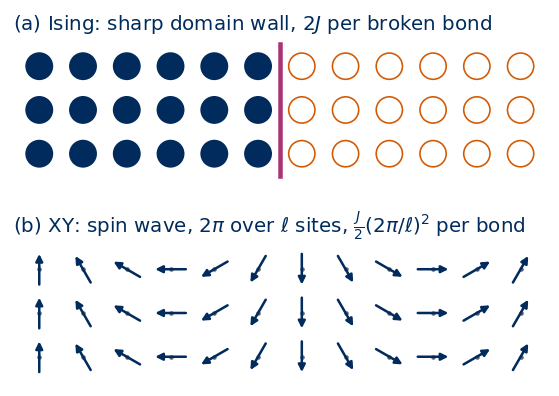

In [2]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def draw_xy_spins(ax, theta, length=0.75, color=NAVY, lw=1.3, head=7, dot=True):
    # planar spins: an arrow of fixed length centred on every lattice site (x, y), angle theta[y, x]
    for (y, x), t in np.ndenumerate(theta):
        dx, dy = 0.5 * length * np.cos(t), 0.5 * length * np.sin(t)
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x - dx, y - dy),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=head, shrinkA=0, shrinkB=0))
        if dot:
            ax.plot(x, y, "o", color=GRAY, ms=1.5, zorder=1)

def plaquette_winding(theta):
    # winding number of every plaquette (lower-left corner (x, y)), corners traversed counter-clockwise
    wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi           # angle difference mapped to [-pi, pi)
    t1, t2 = theta[:-1, :-1], theta[:-1, 1:]                       # (x, y), (x+1, y)
    t3, t4 = theta[1:, 1:], theta[1:, :-1]                         # (x+1, y+1), (x, y+1)
    return np.rint((wrap(t2 - t1) + wrap(t3 - t2) + wrap(t4 - t3) + wrap(t1 - t4)) / (2 * np.pi)).astype(int)

def draw_vortex_marks(ax, w, r=0.3):
    # vortex (w = +1): navy disc with "+";  antivortex (w = -1): white disc with orange rim and "-"
    for (y, x), v in np.ndenumerate(w):
        if v != 0:
            face, edge, txt = (NAVY, NAVY, "white") if v > 0 else ("white", ORANGE, ORANGE)
            ax.add_patch(mpatches.Circle((x + 0.5, y + 0.5), r, fc=face, ec=edge, lw=1.3, zorder=6, alpha=0.9))
            ax.text(x + 0.5, y + 0.5, "+" if v > 0 else "−", color=txt, ha="center", va="center", fontsize=10,
                    fontweight="bold", zorder=7)

def sketch_wall_versus_spin_wave():
    nx, ny = 12, 3
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5.5, 2.9))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.92, hspace=0.45)
    # (a) Ising: the spins flip abruptly across one column of bonds
    for yy in range(ny):
        for xx in range(nx):
            draw_spin(ax1, xx, yy, 1 if xx < nx // 2 else -1, r=0.3, lw=0.9)
    ax1.plot([nx / 2 - 0.5] * 2, [-0.5, ny - 0.5], color=PURPLE, lw=2.5)
    ax1.set_title(r"(a) Ising: sharp domain wall, $2J$ per broken bond", fontsize=11, color=NAVY, loc="left")
    # (b) XY: the angle turns by 2 pi gradually over ell = nx columns, i.e. by 2 pi / ell per bond
    theta = np.tile(2 * np.pi * np.arange(nx) / nx + np.pi / 2, (ny, 1))
    draw_xy_spins(ax2, theta, length=0.7, lw=1.4, head=8)
    ax2.set_title(r"(b) XY: spin wave, $2\pi$ over $\ell$ sites, $\frac{J}{2}(2\pi/\ell)^2$ per bond", fontsize=11, color=NAVY, loc="left")
    for ax in (ax1, ax2):
        ax.set_xlim(-0.6, nx - 0.4); ax.set_ylim(-0.6, ny - 0.4); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_wall_versus_spin_wave()
save_sketch(fig, "sketch_xy_spin_wave.png")
plt.show()


Berezinskii (1971, 1972) and Kosterlitz and Thouless (1973) showed that the 2D XY model nevertheless has two distinct phases, and hence a
transition without an order parameter. At low $T$, correlations decay as a **power law** of distance ("quasi-long-range order"), and the system
resists a twist: it has a non-zero **spin stiffness**. At high $T$, correlations decay **exponentially** and the stiffness vanishes. The transition between them is caused by **vortices**, points around which the angle winds by $2\pi$. Below $T_{\rm BKT}$ vortices exist only in
tightly bound vortex–antivortex pairs; above, free vortices proliferate. Kosterlitz (1974) worked out the critical behaviour with the
renormalisation group, and Nelson and Kosterlitz (1977) predicted that the stiffness drops **discontinuously** at $T_{\rm BKT}$ by a universal amount.

The same physics describes any 2D system whose state is a phase: thin films of superfluid $^4$He
(the phase of the condensate wave function), thin superconducting films, and planar magnets. The Nelson–Kosterlitz prediction refers
directly to superfluid films (title: *Universal jump in the superfluid density of two-dimensional superfluids*), and Bishop and Reppy (1978)
studied the superfluid transition in two-dimensional $^4$He films experimentally.

The importance of these ideas was recognised by the 2016 Nobel Prize in Physics, awarded "with one half to David J. Thouless, and the other half to F. Duncan M. Haldane and
J. Michael Kosterlitz for theoretical discoveries of topological phase transitions and topological phases of matter" (nobelprize.org);
the BKT transition is the **topological phase transition** of that citation.

For the notebooks that follow, the lesson is that a learning algorithm looking at snapshots will find whatever varies most between them.
For the XY model the obvious candidate, the magnetisation, is a finite-size effect, and the relevant objects, vortices, are invisible in a
single spin's value: they are a property of the angles **around a plaquette**. Knowing this physics is the only way to judge what an
algorithm has found.

<hr/>
## 2. Model, symmetries and Monte Carlo sampling

### 2.1 Definition

On an $L\times L$ square lattice with periodic boundaries (a torus), $N=L^2$ planar unit vectors $\boldsymbol s_i=(\cos\theta_i,\sin\theta_i)$,
$\theta_i\in[0,2\pi)$, interact with their nearest neighbours:
$$
\begin{aligned}
H(\boldsymbol\theta)&=-J\sum_{\langle i,j\rangle}\boldsymbol s_i\cdot\boldsymbol s_j\\
&=-J\sum_{\langle i,j\rangle}\cos(\theta_i-\theta_j),\qquad J>0,
\end{aligned}
$$
where $\langle i,j\rangle$ runs over the $2N$ nearest-neighbour bonds. We set $J=1$ and $k_B=1$; the lattice spacing is $a=1$.

The figure below shows the model on a small patch: every site carries an arrow of unit length at angle $\theta_i$, measured from the horizontal axis as on the unit circle on the right, and each bond between nearest neighbours contributes $-J\cos(\theta_i-\theta_j)$ to the energy. Parallel neighbours give $-J$ and antiparallel neighbours $+J$, while a small relative angle $\delta$ costs only $\frac J2\delta^2$ above the minimum; this is why the gradual twists of Section 1 are so cheap.

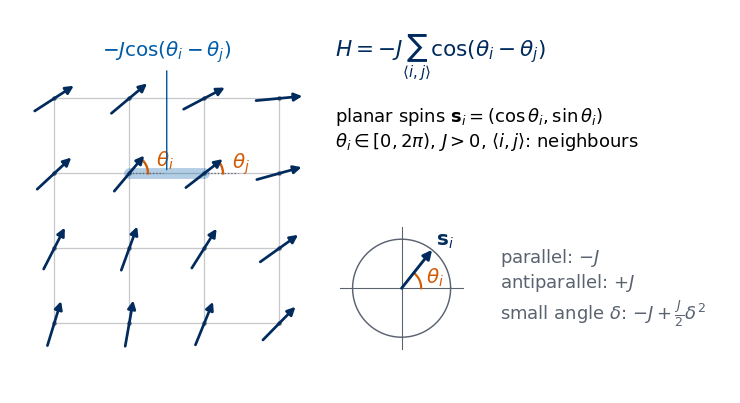

In [3]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_xy_spins(ax, theta, length=0.75, color=NAVY, lw=1.3, head=7, dot=True):
    # planar spins: an arrow of fixed length centred on every lattice site (x, y), angle theta[y, x]
    for (y, x), t in np.ndenumerate(theta):
        dx, dy = 0.5 * length * np.cos(t), 0.5 * length * np.sin(t)
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x - dx, y - dy),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=head, shrinkA=0, shrinkB=0))
        if dot:
            ax.plot(x, y, "o", color=GRAY, ms=1.5, zorder=1)

def plaquette_winding(theta):
    # winding number of every plaquette (lower-left corner (x, y)), corners traversed counter-clockwise
    wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi           # angle difference mapped to [-pi, pi)
    t1, t2 = theta[:-1, :-1], theta[:-1, 1:]                       # (x, y), (x+1, y)
    t3, t4 = theta[1:, 1:], theta[1:, :-1]                         # (x+1, y+1), (x, y+1)
    return np.rint((wrap(t2 - t1) + wrap(t3 - t2) + wrap(t4 - t3) + wrap(t1 - t4)) / (2 * np.pi)).astype(int)

def draw_vortex_marks(ax, w, r=0.3):
    # vortex (w = +1): navy disc with "+";  antivortex (w = -1): white disc with orange rim and "-"
    for (y, x), v in np.ndenumerate(w):
        if v != 0:
            face, edge, txt = (NAVY, NAVY, "white") if v > 0 else ("white", ORANGE, ORANGE)
            ax.add_patch(mpatches.Circle((x + 0.5, y + 0.5), r, fc=face, ec=edge, lw=1.3, zorder=6, alpha=0.9))
            ax.text(x + 0.5, y + 0.5, "+" if v > 0 else "−", color=txt, ha="center", va="center", fontsize=10,
                    fontweight="bold", zorder=7)

def sketch_xy_model():
    L = 4
    y, x = np.indices((L, L))
    theta = 0.6 + 0.45 * np.sin(2 * np.pi * x / 7 + 0.8) + 0.35 * np.cos(2 * np.pi * y / 6)   # slowly varying angles
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.43, 1.0]); tx = fig.add_axes([0.45, 0.0, 0.55, 1.0]); tx.axis("off")
    for k in range(L):
        ax.plot([0, L - 1], [k, k], color=GRAY, lw=0.7, alpha=0.35); ax.plot([k, k], [0, L - 1], color=GRAY, lw=0.7, alpha=0.35)
    i, j = (1, 2), (2, 2)                                           # the highlighted bond <i, j>
    ax.plot(*zip(i, j), color=BLUE, lw=6, alpha=0.3, solid_capstyle="round")
    draw_xy_spins(ax, theta, length=0.62, lw=1.5, head=9)
    for (px, py), name in [(i, "i"), (j, "j")]:
        t = theta[py, px]
        ax.plot([px, px + 0.45], [py, py], color=GRAY, lw=0.7, ls=":")         # reference direction theta = 0
        arc = np.linspace(0, t, 30)
        ax.plot(px + 0.25 * np.cos(arc), py + 0.25 * np.sin(arc), color=ORANGE, lw=1.3)
        ax.text(px + 0.36 * np.cos(t / 2) + 0.03, py + 0.36 * np.sin(t / 2) - 0.06, rf"$\theta_{name}$", fontsize=11, color=ORANGE)
    ax.annotate(r"$-J\cos(\theta_i-\theta_j)$", xy=(1.5, 2.0), xytext=(1.5, 3.55), fontsize=11, color=BLUE, ha="center",
                arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.8), bbox=dict(fc="white", ec="none", pad=1))
    ax.set_xlim(-0.55, L - 0.45); ax.set_ylim(-0.55, L - 0.2); ax.set_aspect("equal"); ax.axis("off")

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.88, r"$H=-J\sum_{\langle i,j\rangle}\cos(\theta_i-\theta_j)$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.69, r"planar spins $\mathbf{s}_i=(\cos\theta_i,\sin\theta_i)$" "\n" r"$\theta_i\in[0,2\pi)$, $J>0$, $\langle i,j\rangle$: neighbours",
            fontsize=10, va="center")
    # a unit circle showing one spin and its angle
    cx, cy, R = 0.17, 0.27, 0.13
    phi = np.linspace(0, 2 * np.pi, 200)
    asp = 2.9 / (0.55 * 5.5)                                        # axes height / width, to draw a round circle
    tx.plot(cx + R * asp * np.cos(phi), cy + R * np.sin(phi), color=GRAY, lw=0.8)
    tx.plot([cx - 1.25 * R * asp, cx + 1.25 * R * asp], [cy, cy], color=GRAY, lw=0.6)
    tx.plot([cx, cx], [cy - 1.25 * R, cy + 1.25 * R], color=GRAY, lw=0.6)
    t0 = 0.9
    tx.annotate("", xy=(cx + R * asp * np.cos(t0), cy + R * np.sin(t0)), xytext=(cx, cy),
                arrowprops=dict(arrowstyle="-|>", color=NAVY, lw=1.6, mutation_scale=10, shrinkA=0, shrinkB=0))
    arc = np.linspace(0, t0, 30)
    tx.plot(cx + 0.4 * R * asp * np.cos(arc), cy + 0.4 * R * np.sin(arc), color=ORANGE, lw=1.2)
    tx.text(cx + 0.5 * R * asp, cy + 0.1 * R, r"$\theta_i$", fontsize=11, color=ORANGE)
    tx.text(cx + R * asp * np.cos(t0) + 0.01, cy + R * np.sin(t0) + 0.01, r"$\mathbf{s}_i$", fontsize=11, color=NAVY)
    tx.text(0.42, 0.27, "parallel: $-J$\nantiparallel: $+J$\nsmall angle $\\delta$: $-J+\\frac{J}{2}\\delta^2$",
            fontsize=10, va="center", color=GRAY)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_xy_model()
save_sketch(fig, "sketch_xy_card.png")
plt.show()


The energy is invariant under several transformations. The **global rotation** $\theta_i\to\theta_i+\alpha$ for all $i$, with any $\alpha$, is a
**continuous** symmetry, the rotation part $U(1)\cong SO(2)$ of the group $O(2)$; together with the **global reflection** $\theta_i\to-\theta_i$ it forms $O(2)$.
The **periodicity** $\theta_i\to\theta_i+2\pi$ on any single site looks harmless, but it is what allows vortices (Section 4). Finally there are the
lattice symmetries: translations, rotations by $90^\circ$ and mirror reflections.

Every term of $H$ is at least $-J$, so the minimum energy $E_0=-2JN$ is reached when all spins are parallel, $\theta_i=\theta_0$.
The ground state is not unique: it is a **continuous family** labelled by $\theta_0\in[0,2\pi)$ (compare the two ground states of Ising).

The basic observables are the magnetisation vector and the energy per spin,
$$
\boldsymbol m=\frac1N\sum_i\boldsymbol s_i,\qquad |\boldsymbol m|=\sqrt{m_x^2+m_y^2},\qquad e=\frac{H}{N}.
$$
Because of the rotation symmetry $\langle\boldsymbol m\rangle=0$ on any finite lattice; the useful quantities are $\langle|\boldsymbol m|\rangle$ and $\langle\boldsymbol m^2\rangle$.

In the code, angles are stored as an array `theta` of shape `(..., L, L)`, axis `-1` is the $x$ direction (columns) and axis `-2`
the $y$ direction (rows). `jnp.roll(theta, -1, -1)` is the right neighbour of every site, so `jnp.roll(theta, -1, -1) - theta` lists the
angle differences on all $N$ horizontal bonds at once (and similarly for the $N$ vertical bonds). The cell below checks the ground-state energy, the energy of a random
state, and the invariance of $H$ under the global rotation, the reflection and a shift by $2\pi$ on one site.
For a random state with independent angles uniform in $[0,2\pi)$ each bond term $\cos(\theta_i-\theta_j)$ has mean $0$ and variance $1/2$, and the $2N$ bond terms are uncorrelated, so $e=-(J/N)\sum_{\langle i,j\rangle}\cos(\theta_i-\theta_j)$ has mean $0$ and variance $(J/N)^2\cdot 2N\cdot\frac12=J^2/N$: a standard deviation $J/\sqrt N=0.0625\,J$ for $N=16^2$.

In [4]:
TWO_PI = 2 * np.pi

def wrap(a):
    # map angles to the interval [-pi, pi)
    return (a + jnp.pi) % TWO_PI - jnp.pi

def bond_differences(theta):
    # theta: (..., L, L).  Returns dx = theta_{r+x} - theta_r and dy = theta_{r+y} - theta_r, each (..., L, L): one entry per bond
    return jnp.roll(theta, -1, -1) - theta, jnp.roll(theta, -1, -2) - theta

def energy_per_spin(theta):
    # e = H / N = -(J/N) sum over the 2N bonds of cos(theta_i - theta_j);  output shape (...)
    dx, dy = bond_differences(theta)
    return -J * (jnp.cos(dx) + jnp.cos(dy)).mean((-2, -1))

def magnetisation(theta):
    # m = (1/N) sum_i (cos theta_i, sin theta_i);  returns (m_x, m_y), each of shape (...)
    return jnp.cos(theta).mean((-2, -1)), jnp.sin(theta).mean((-2, -1))

# --- checks of the definitions and of the symmetries on a 16 x 16 lattice ---
L0 = 16
key = jax.random.PRNGKey(0)
theta_rand = jax.random.uniform(key, (L0, L0), maxval=TWO_PI)          # a random (infinite-temperature) configuration
theta_gs = jnp.full((L0, L0), 0.7)                                      # a ground state, theta_0 = 0.7

print(f"ground state:      e = {float(energy_per_spin(theta_gs)):+.6f}   (expected -2J = {-2*J:+.1f}),  "
      f"|m| = {float(jnp.hypot(*magnetisation(theta_gs))):.6f}")
print(f"random state:      e = {float(energy_per_spin(theta_rand)):+.4f}   (expected 0 +- J/sqrt(N) = +-{J * np.sqrt(1 / L0**2):.4f})")
print(f"global rotation:   |e(theta + 1.234) - e(theta)| = {abs(float(energy_per_spin(theta_rand + 1.234) - energy_per_spin(theta_rand))):.1e}")
print(f"global reflection: |e(-theta) - e(theta)|        = {abs(float(energy_per_spin(-theta_rand) - energy_per_spin(theta_rand))):.1e}")
theta_shift = theta_rand.at[3, 5].add(TWO_PI)                           # add 2 pi to one site only
print(f"2 pi on one site:  |e(shifted) - e(theta)|       = {abs(float(energy_per_spin(theta_shift) - energy_per_spin(theta_rand))):.1e}")

ground state:      e = -2.000000   (expected -2J = -2.0),  |m| = 1.000000
random state:      e = -0.1139   (expected 0 +- J/sqrt(N) = +-0.0625)


global rotation:   |e(theta + 1.234) - e(theta)| = 4.5e-08
global reflection: |e(-theta) - e(theta)|        = 0.0e+00
2 pi on one site:  |e(shifted) - e(theta)|       = 0.0e+00


### 2.2 Checkerboard Metropolis updates

To sample the Boltzmann distribution we start from the Metropolis algorithm, which Lab 010 derived for Ising spins and which works for any energy.
We propose a new angle for spin $i$, $\theta_i'=\theta_i+\delta\,(2u-1)$
with $u$ uniform in $[0,1)$ and a step width $\delta$, and accept with probability $\min\!\left(1,e^{-\beta\Delta E_i}\right)$. The proposal is
symmetric, so detailed balance holds. The energy change only involves the four neighbours $j$ of $i$ and is expressed through the **local field**
$$
\begin{aligned}
\boldsymbol h_i&=\sum_{j\in{\rm nn}(i)}\boldsymbol s_j=\Big(\sum_j\cos\theta_j,\ \sum_j\sin\theta_j\Big),\\
\Delta E_i&=-J\,\boldsymbol h_i\cdot(\boldsymbol s_i'-\boldsymbol s_i).
\end{aligned}
$$

Since nearest neighbours always have different colours on a chessboard ($(x+y)\bmod 2$), all spins of one colour can be updated
**simultaneously**: none of them appears in another's local field. One **sweep** updates all black sites and then all white sites, i.e. one
attempted move per spin. In code we propose new angles for all sites and accept only on the current colour (a mask); this wastes half of the
random numbers but keeps the code short.

### 2.3 Wolff cluster updates

Local moves have a weakness. Near $T_{\rm BKT}$ the correlation length is comparable with $L$, and below $T_{\rm BKT}$ it is infinite. Rotating a large
correlated region one spin at a time is slow: the autocorrelation time of Metropolis grows with $L$, as we measure below.

Wolff's idea (Wolff 1989) is to turn the XY model into an Ising model for one update. Choose a random direction
$\boldsymbol r=(\cos\varphi,\sin\varphi)$ and consider only **reflections** of spins across the line perpendicular to $\boldsymbol r$:
$$
\begin{aligned}
&\boldsymbol s_i\to\boldsymbol s_i-2(\boldsymbol s_i\cdot\boldsymbol r)\,\boldsymbol r\\
\Longleftrightarrow\quad &\theta_i\to\pi+2\varphi-\theta_i .
\end{aligned}
$$
Write $\sigma_i=\boldsymbol s_i\cdot\boldsymbol r=\cos(\theta_i-\varphi)$. If a spin is reflected and its neighbour is not, the bond energy
changes by $2J\sigma_i\sigma_j$; reflecting both leaves it unchanged. With respect to reflections the XY model is therefore an **Ising model with
bond-dependent couplings** $J\sigma_i\sigma_j$, and the Swendsen–Wang/Wolff construction of Lab 018 applies:
1. pick a random seed site;
2. activate each bond $\langle i,j\rangle$ with probability $p_{ij}=1-\exp\!\big(\min(0,\,-2\beta J\sigma_i\sigma_j)\big)$ (only bonds with $\sigma_i\sigma_j>0$ can be active);
3. reflect the whole cluster of sites connected to the seed by active bonds.

The update satisfies detailed balance and needs no acceptance step (Wolff 1989). Combined with a random $\varphi$ it is ergodic together with
the Metropolis moves.

The cluster search needs some care in JAX, because a sequential "grow the cluster" loop is awkward to vectorise over many chains. We use the fact that the bond
variables are independent: drawing **all** bonds of the lattice first and then taking the connected component of the seed gives exactly the
same cluster distribution as growing it bond by bond. The connected components are found as in Lab 018 by **label propagation**: every site
starts with its own index as label and repeatedly takes the smallest label among itself and its bonded neighbours, followed by
*pointer jumping* (a site adopts the label of its label), until no label changes. The price: under `vmap` every chain waits until the
slowest chain has converged, and at low $T$ the clusters span the lattice and need many iterations. On a CPU this makes one Wolff update
much more expensive than one Metropolis sweep (measured in Section 2.6).

### 2.4 Over-relaxation

A cheap alternative for speeding up the sampling (Creutz 1987; Brown and Woch 1987) is to **reflect each spin about its local
field**. With $\varphi_i$ the direction of $\boldsymbol h_i$,
$$
\begin{aligned}
&\theta_i\to2\varphi_i-\theta_i\\
\Longrightarrow\quad &\boldsymbol h_i\cdot\boldsymbol s_i\ \text{unchanged},\quad\Delta E_i=0 .
\end{aligned}
$$
The move is deterministic, its own inverse, and conserves the energy, so it is accepted with probability $1$ and leaves the Boltzmann
distribution invariant. It does not change the energy, so on its own it is not ergodic (it samples at fixed energy); combined with Metropolis
sweeps it is. It moves spins by large angles at no cost; Section 2.6 measures how much this shortens the autocorrelation times.
The checkerboard applies as for Metropolis.

In [5]:
def checkerboard(L):
    # (L, L) array with values 0 / 1 = colour (x + y) mod 2
    return (jnp.arange(L)[:, None] + jnp.arange(L)[None, :]) % 2

def local_field(theta):
    # h_i = sum of the 4 neighbour vectors;  returns (h_x, h_y), each of the same shape as theta (..., L, L)
    c, s = jnp.cos(theta), jnp.sin(theta)
    nbrs = ((1, -2), (-1, -2), (1, -1), (-1, -1))          # (shift, axis) for the up / down / left / right neighbours
    return sum(jnp.roll(c, d, ax) for d, ax in nbrs), sum(jnp.roll(s, d, ax) for d, ax in nbrs)

def metropolis_sweep(theta, key, beta, delta):
    # theta: (L, L);  one sweep = black sites, then white sites.  Returns new theta and the acceptance rate.
    colour = checkerboard(theta.shape[-1])
    k_prop, k_acc = jax.random.split(key)
    # every site is updated exactly once per sweep, so one proposal and one acceptance number per site suffice
    new = theta + delta * (2.0 * jax.random.uniform(k_prop, theta.shape) - 1.0)
    u_acc = jax.random.uniform(k_acc, theta.shape)
    n_acc = 0.0
    for c in (0, 1):                                          # Python loop, unrolled by jit
        hx, hy = local_field(theta)
        dE = -J * (hx * (jnp.cos(new) - jnp.cos(theta)) + hy * (jnp.sin(new) - jnp.sin(theta)))
        accept = (u_acc < jnp.exp(-beta * dE)) & (colour == c)
        theta = jnp.where(accept, jnp.mod(new, TWO_PI), theta)
        n_acc = n_acc + accept.sum()
    return theta, n_acc / theta.size

def overrelaxation_sweep(theta):
    # reflect every spin about its local field, black sites then white sites: theta_i -> 2 phi_i - theta_i,
    # with phi_i = atan2(h_y, h_x) the direction of the local field.  The energy is unchanged; no random numbers.
    colour = checkerboard(theta.shape[-1])
    for c in (0, 1):
        hx, hy = local_field(theta)
        theta = jnp.where(colour == c, jnp.mod(2.0 * jnp.arctan2(hy, hx) - theta, TWO_PI), theta)
    return theta

def connected_labels(bond_x, bond_y):
    # bond_x[y, x]: site (y, x) bonded to (y, x+1);  bond_y[y, x]: site (y, x) bonded to (y+1, x);  periodic lattice.
    # Returns (L, L) int labels: two sites have the same label iff they are connected by active bonds.
    L = bond_x.shape[0]
    big = L * L
    bond_xm, bond_ym = jnp.roll(bond_x, 1, 1), jnp.roll(bond_y, 1, 0)        # bonds to the left / lower neighbour
    def body(carry):
        lab, _ = carry
        new = lab
        new = jnp.minimum(new, jnp.where(bond_x, jnp.roll(lab, -1, 1), big))
        new = jnp.minimum(new, jnp.where(bond_xm, jnp.roll(lab, 1, 1), big))
        new = jnp.minimum(new, jnp.where(bond_y, jnp.roll(lab, -1, 0), big))
        new = jnp.minimum(new, jnp.where(bond_ym, jnp.roll(lab, 1, 0), big))
        new = new.ravel()[new]                                                  # pointer jumping
        return new, jnp.any(new != lab)
    lab, _ = lax.while_loop(lambda c: c[1], body, (jnp.arange(big).reshape(L, L), True))
    return lab

def wolff_update(theta, key, beta):
    # one Wolff single-cluster update of theta (L, L).  Returns new theta and the cluster size / N.
    L = theta.shape[-1]
    k_phi, k_x, k_y, k_seed = jax.random.split(key, 4)
    phi = jax.random.uniform(k_phi, (), maxval=TWO_PI)                         # reflection direction r = (cos phi, sin phi)
    sigma = jnp.cos(theta - phi)                                               # sigma_i = s_i . r
    p_x = 1.0 - jnp.exp(jnp.minimum(0.0, -2.0 * beta * J * sigma * jnp.roll(sigma, -1, 1)))
    p_y = 1.0 - jnp.exp(jnp.minimum(0.0, -2.0 * beta * J * sigma * jnp.roll(sigma, -1, 0)))
    bond_x = jax.random.uniform(k_x, theta.shape) < p_x
    bond_y = jax.random.uniform(k_y, theta.shape) < p_y
    lab = connected_labels(bond_x, bond_y)
    seed = jax.random.randint(k_seed, (), 0, L * L)
    in_cluster = lab == lab.ravel()[seed]
    theta = jnp.where(in_cluster, jnp.mod(jnp.pi + 2.0 * phi - theta, TWO_PI), theta)
    return theta, in_cluster.mean()

After every Monte Carlo step (one Metropolis sweep followed by `n_or` over-relaxation sweeps and `n_wolff` Wolff
updates) we record ten numbers per chain.
With $\Delta^x_r=\theta_{r+\hat x}-\theta_r$ and $\Delta^y_r=\theta_{r+\hat y}-\theta_r$ the bond angles, these are the bond sums
$$
\begin{aligned}
C_x&=\sum_r\cos\Delta^x_r,\quad C_y=\sum_r\cos\Delta^y_r,\\
S_x&=\sum_r\sin\Delta^x_r,\quad S_y=\sum_r\sin\Delta^y_r,\\
E&=-J(C_x+C_y),
\end{aligned}
$$
together with the magnetisation $(m_x,m_y)$, the vortex density $n_v$ (number of plaquettes with non-zero winding number per site, defined in Section 4),
the Metropolis acceptance rate and the Wolff cluster size. $S_x,S_y$ enter the helicity modulus (Section 5).

The function `simulate` runs many independent chains at once: `jax.vmap` over chains (each with its own $\beta$ and random key), `lax.scan` over Monte
Carlo steps, everything compiled by `jax.jit`. The input `theta0` has shape `(C, L, L)`, `keys` `(C, 2)`, `betas` `(C,)`; the output time series
has shape `(C, n_meas, 10)` and the stored snapshots `(C, n_store, L, L)`, taken every `n_meas // n_store` steps.

In [6]:
def vorticity(theta):
    # winding number of every plaquette (Section 4).  Plaquette (y, x) has corners (y,x) -> (y,x+1) -> (y+1,x+1) -> (y+1,x),
    # traversed counter-clockwise (x to the right, y upwards).  Output: int32 array (..., L, L) with values in {-1, 0, +1} (rarely +-2).
    t00 = theta
    t01 = jnp.roll(theta, -1, -1)                    # (y, x+1)
    t11 = jnp.roll(t01, -1, -2)                      # (y+1, x+1)
    t10 = jnp.roll(theta, -1, -2)                    # (y+1, x)
    circ = wrap(t01 - t00) + wrap(t11 - t01) + wrap(t10 - t11) + wrap(t00 - t10)
    return jnp.round(circ / TWO_PI).astype(jnp.int32)

OBS = ["E", "Cx", "Cy", "Sx", "Sy", "mx", "my", "nv", "acc", "cluster"]       # the ten recorded numbers

def measure(theta):
    dx, dy = bond_differences(theta)
    cx, cy = jnp.cos(dx).sum(), jnp.cos(dy).sum()
    sx, sy = jnp.sin(dx).sum(), jnp.sin(dy).sum()
    mx, my = magnetisation(theta)
    nv = (vorticity(theta) != 0).mean()
    return jnp.stack([-J * (cx + cy), cx, cy, sx, sy, mx, my, nv])

@partial(jax.jit, static_argnames=("n_equil", "n_meas", "n_store", "n_wolff", "n_or"))
def simulate(theta0, keys, betas, delta, n_equil, n_meas, n_store, n_wolff, n_or):
    gap = n_meas // n_store
    def one_chain(theta, key, beta):
        def mc_step(carry, _):
            theta, key = carry
            key, k_m, k_w = jax.random.split(key, 3)
            theta, acc = metropolis_sweep(theta, k_m, beta, delta)
            for _ in range(n_or):                                           # n_or over-relaxation sweeps
                theta = overrelaxation_sweep(theta)
            size = 0.0
            for k in jax.random.split(k_w, max(n_wolff, 1))[:n_wolff]:     # n_wolff cluster updates (0 = Metropolis only)
                theta, size = wolff_update(theta, k, beta)
            return (theta, key), jnp.concatenate([measure(theta), jnp.stack([acc, size])])
        carry, _ = lax.scan(mc_step, (theta, key), None, length=n_equil)    # equilibration, measurements discarded
        def block(carry, _):
            carry, series = lax.scan(mc_step, carry, None, length=gap)
            return carry, (series, carry[0])
        carry, (series, snaps) = lax.scan(block, carry, None, length=n_store)
        return series.reshape(n_store * gap, len(OBS)), snaps, carry[0]
    return jax.vmap(one_chain)(theta0, keys, betas)

def run_chains(L, T_list, n_chains, n_equil, n_meas, n_store, n_wolff=0, n_or=0, delta=1.0, seed=0, start="ordered"):
    # n_chains independent chains for every temperature in T_list.
    # Returns series (nT, n_chains, n_meas, 10) and snapshots (nT, n_chains, n_store, L, L), as numpy arrays.
    T_list = np.asarray(T_list, np.float32)
    C = len(T_list) * n_chains
    betas = jnp.asarray(np.repeat(1.0 / T_list, n_chains))
    k_init, k_run = jax.random.split(jax.random.PRNGKey(seed))
    if start == "ordered":
        theta0 = jnp.zeros((C, L, L))
    else:
        theta0 = jax.random.uniform(k_init, (C, L, L), maxval=TWO_PI)
    series, snaps, _ = simulate(theta0, jax.random.split(k_run, C), betas, delta, n_equil, n_meas, n_store, n_wolff, n_or)
    series = np.asarray(series).reshape(len(T_list), n_chains, n_meas, len(OBS))
    snaps = np.asarray(snaps).reshape(len(T_list), n_chains, n_store, L, L)
    return series, snaps

### 2.5 Low- and high-temperature limits

Before trusting the sampler we test it. There is no exact solution of the 2D XY model, but two limits are exact enough to test the code, and the
three update schemes must agree with each other.

At low temperature, expanding $\cos x\approx1-x^2/2$ (Section 3) gives a quadratic energy with $N-1$ non-zero modes, each carrying $T/2$ by
equipartition, so $\;e\approx-2J+\tfrac{T}{2}\,\tfrac{N-1}{N}$, with corrections of order $T^2$. At high temperature the bonds become nearly independent, and for independent bonds $\langle\cos(\theta_i-\theta_j)\rangle=\dfrac{\int_0^{2\pi}\cos x\,e^{\beta J\cos x}dx}{\int_0^{2\pi}e^{\beta J\cos x}dx}=\dfrac{I_1(\beta J)}{I_0(\beta J)}$,
with $I_n$ the modified Bessel functions. This is exact on a lattice without closed loops (for instance an open chain); on the square
lattice closed loops of bonds give corrections that become small at high $T$. So $e\approx-2J\,I_1(\beta J)/I_0(\beta J)$.
Finally, Metropolis alone, Metropolis + over-relaxation and Metropolis + Wolff are all exact algorithms, so at $T=0.9$ they must give the same
averages within errors.

The SymPy cell checks the Bessel-function ratio symbolically, as an expansion in $\beta J$.

In [7]:
x, b = sp.symbols("x beta", positive=True)
num = sp.integrate(sp.cos(x) * sp.series(sp.exp(b * sp.cos(x)), b, 0, 6).removeO(), (x, 0, 2 * sp.pi))
den = sp.integrate(sp.series(sp.exp(b * sp.cos(x)), b, 0, 6).removeO(), (x, 0, 2 * sp.pi))
ratio = sp.series(num / den, b, 0, 5)
print("<cos(theta_i - theta_j)> for one free bond, expanded in beta J :", ratio)
I1_ser = sp.series(sp.besseli(1, b), b, 0, 7).removeO()            # power series of the Bessel functions
I0_ser = sp.series(sp.besseli(0, b), b, 0, 7).removeO()
print("series of I_1/I_0 (SymPy besseli)                              :", sp.series(I1_ser / I0_ser, b, 0, 5))

<cos(theta_i - theta_j)> for one free bond, expanded in beta J : beta/2 - beta**3/16 + O(beta**5)
series of I_1/I_0 (SymPy besseli)                              : beta/2 - beta**3/16 + O(beta**5)


In [8]:
def jackknife(f, chain_means):
    # chain_means: (n_chains, k) per-chain averages;  f maps a (k,) vector of averages to an estimate.
    # Returns (estimate, jackknife error) using leave-one-chain-out averages.
    n = chain_means.shape[0]
    full = f(chain_means.mean(0))
    loo = (chain_means.sum(0)[None, :] - chain_means) / (n - 1)
    vals = np.array([f(v) for v in loo])
    return full, np.sqrt((n - 1) / n * ((vals - vals.mean(0)) ** 2).sum(0))

t0 = time.time()
T_chk = [0.1, 0.2, 3.0, 5.0]
ser, _ = run_chains(16, T_chk, n_chains=32, n_equil=500, n_meas=500, n_store=1, n_or=1, seed=1)
N16 = 16 * 16
for i, T in enumerate(T_chk):
    e_mc, de = jackknife(lambda v: v[0] / N16, ser[i, :, :, 0].mean(1)[:, None])
    ref = -2 * J + T / 2 * (N16 - 1) / N16 if T < 1 else -2 * J * i1(1 / T) / i0(1 / T)
    name = "equipartition -2J + T/2" if T < 1 else "independent bonds -2J I1/I0"
    print(f"T = {T:3.1f}:  e_MC = {e_mc:+.5f} +- {de:.5f}   {name} = {ref:+.5f}   difference = {e_mc - ref:+.5f}")
print(f"({time.time() - t0:.1f} s)")

T = 0.1:  e_MC = -1.94939 +- 0.00010   equipartition -2J + T/2 = -1.95020   difference = +0.00080
T = 0.2:  e_MC = -1.89772 +- 0.00016   equipartition -2J + T/2 = -1.90039   difference = +0.00267
T = 3.0:  e_MC = -0.34866 +- 0.00198   independent bonds -2J I1/I0 = -0.32879   difference = -0.01987
T = 5.0:  e_MC = -0.20280 +- 0.00144   independent bonds -2J I1/I0 = -0.19901   difference = -0.00380
(5.5 s)


At $T=0.1$ and $0.2$ the deviation from equipartition is of order $T^2$, as it should be (the anharmonic terms of $\cos$). At high $T$ the
independent-bond formula is close and the remaining difference comes from closed loops of bonds. Next we compare the three update schemes at $T=0.9$, close to the transition, where sampling is hardest.
`SCHEMES` maps a name to `(n_wolff, n_or)`, the number of Wolff updates and over-relaxation sweeps per Metropolis sweep.

In [9]:
def helicity_from_means(v, beta, N):
    # v = per-chain or pooled averages of (C_x + C_y, S_x^2 + S_y^2);  Section 5 derives Upsilon = [<C> - beta <S^2>] / (2N)
    return (v[0] - beta * v[1]) / (2 * N)

def chain_moments(series):
    # series: (n_chains, n_meas, 10)  ->  per-chain means (n_chains, 9) of the quantities needed below
    E, Cx, Cy, Sx, Sy, mx, my, nv, acc = (series[..., k] for k in range(9))
    m2 = mx**2 + my**2
    cols = [E, E**2, Cx + Cy, Sx**2 + Sy**2, np.sqrt(m2), m2, m2**2, nv, acc]
    return np.stack([c.mean(-1) for c in cols], -1)

MOMENTS = ["E", "E2", "C", "S2", "absm", "m2", "m4", "nv", "acc"]

SCHEMES = {"Metropolis": (0, 0), "Metropolis + over-relaxation": (0, 1), "Metropolis + Wolff": (1, 0)}

t0 = time.time()
for name, (n_wolff, n_or) in SCHEMES.items():
    ser, _ = run_chains(16, [0.9], n_chains=32, n_equil=500, n_meas=2000, n_store=1, n_wolff=n_wolff, n_or=n_or, seed=2)
    cm = chain_moments(ser[0])
    e, de = jackknife(lambda v: v[0] / N16, cm)
    ups, dups = jackknife(lambda v: helicity_from_means(v[[2, 3]], 1 / 0.9, N16), cm)
    m2, dm2 = jackknife(lambda v: v[5], cm)
    print(f"{name:29s}:  e = {e:+.4f} +- {de:.4f}   Upsilon = {ups:.4f} +- {dups:.4f}   <m^2> = {m2:.4f} +- {dm2:.4f}")
print(f"({time.time() - t0:.1f} s)")

Metropolis                   :  e = -1.4443 +- 0.0010   Upsilon = 0.6435 +- 0.0044   <m^2> = 0.5165 +- 0.0021


Metropolis + over-relaxation :  e = -1.4435 +- 0.0007   Upsilon = 0.6407 +- 0.0016   <m^2> = 0.5143 +- 0.0008


Metropolis + Wolff           :  e = -1.4433 +- 0.0006   Upsilon = 0.6403 +- 0.0010   <m^2> = 0.5140 +- 0.0008
(23.8 s)


### 2.6 Autocorrelation times and cost

The three schemes agree within the errors in $e$, $\Upsilon$ and $\langle\boldsymbol m^2\rangle$, so they differ only in efficiency, and efficiency is what we measure next.
Consecutive Monte Carlo configurations are correlated. For an observable $A$ with time series $A_t$, the normalised autocorrelation function
and the **integrated autocorrelation time** are
$$
\begin{aligned}
\rho(t)&=\frac{\langle A_sA_{s+t}\rangle-\langle A\rangle^2}{\langle A^2\rangle-\langle A\rangle^2},\\
\tau_{\rm int}&=\frac12+\sum_{t=1}^{W}\rho(t),
\end{aligned}
$$
where the window $W$ is the first $t$ with $t\ge6\,\tau_{\rm int}(t)$ (a standard self-consistent cut-off that avoids summing pure noise).
A run of $n$ steps contains about $n/(2\tau_{\rm int})$ independent measurements. We measure $\tau_{\rm int}$ of $|\boldsymbol m|^2$, the slowest
common observable, at $T=0.9\approx T_{\rm BKT}$ for $L=16$ and $L=32$, and compare it with the CPU time of one step. The figure of merit is the
CPU time per independent sample, $2\tau_{\rm int}\times$(time per step).

In [10]:
def tau_int(series):
    # series: (n_chains, n_t).  Autocorrelation averaged over chains, then the self-consistent window.
    a = series - series.mean()
    n_t = a.shape[1]
    f = np.fft.rfft(a, 2 * n_t, axis=1)
    acf = np.fft.irfft(f * np.conj(f), axis=1)[:, :n_t].mean(0)
    rho = acf / acf[0]
    tau = 0.5
    for t in range(1, n_t):
        tau += rho[t]
        if t >= 6 * tau:
            break
    return tau, rho

TAU = {}
n_eq_tau, n_meas_tau = 500, 2500
for L in (16, 32):
    for name, (n_wolff, n_or) in SCHEMES.items():
        run_chains(L, [0.9], 16, 10, 10, 1, n_wolff, n_or, seed=3)                       # compile first, then time
        t0 = time.time()
        ser, _ = run_chains(L, [0.9], 16, n_eq_tau, n_meas_tau, 1, n_wolff, n_or, seed=3)
        dt = (time.time() - t0) / (n_eq_tau + n_meas_tau)                                # seconds per step (16 chains)
        tau, rho = tau_int(ser[0, :, :, 5] ** 2 + ser[0, :, :, 6] ** 2)
        TAU[(L, name)] = (tau, rho, dt)
        print(f"L = {L:2d}, {name:29s}:  tau_int(|m|^2) = {tau:6.1f} steps,  time per step (16 chains) = {1e3 * dt:6.2f} ms,  "
              f"time per independent sample = {2 * tau * dt * 1e3:7.1f} ms")
NUMBERS.update({f"tau_L{L}_{name.replace(' + ', '_').replace(' ', '_')}": round(float(TAU[(L, name)][0]), 1) for (L, name) in TAU})

L = 16, Metropolis                   :  tau_int(|m|^2) =   38.5 steps,  time per step (16 chains) =   1.12 ms,  time per independent sample =    86.0 ms


L = 16, Metropolis + over-relaxation :  tau_int(|m|^2) =    3.6 steps,  time per step (16 chains) =   1.44 ms,  time per independent sample =    10.4 ms


L = 16, Metropolis + Wolff           :  tau_int(|m|^2) =    3.1 steps,  time per step (16 chains) =   3.56 ms,  time per independent sample =    22.1 ms


L = 32, Metropolis                   :  tau_int(|m|^2) =  113.0 steps,  time per step (16 chains) =   2.53 ms,  time per independent sample =   571.8 ms


L = 32, Metropolis + over-relaxation :  tau_int(|m|^2) =    6.2 steps,  time per step (16 chains) =   3.60 ms,  time per independent sample =    44.8 ms


L = 32, Metropolis + Wolff           :  tau_int(|m|^2) =    4.2 steps,  time per step (16 chains) =  49.19 ms,  time per independent sample =   415.5 ms


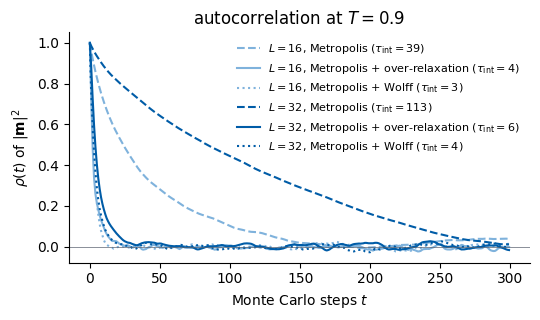

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 3.3))
styles = {"Metropolis": "--", "Metropolis + over-relaxation": "-", "Metropolis + Wolff": ":"}
for (L, name), (tau, rho, _) in TAU.items():
    ax.plot(rho[:300], color=L_COLORS[L], ls=styles[name], label=f"$L={L}$, {name} ($\\tau_{{\\rm int}}={tau:.0f}$)")
ax.axhline(0, color=UJGray, lw=0.5)
ax.set_xlabel("Monte Carlo steps $t$"); ax.set_ylabel(r"$\rho(t)$ of $|\mathbf{m}|^2$"); ax.set_title(r"autocorrelation at $T=0.9$")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "xy_autocorrelation.png"); plt.show()

With Metropolis alone $\tau_{\rm int}$ roughly triples when $L$ doubles from 16 to 32: critical slowing down. One over-relaxation sweep per
step shortens $\tau_{\rm int}$ by more than an order of magnitude at a small extra cost per step. The Wolff update gives the shortest
$\tau_{\rm int}$, but the array-based cluster search makes each step several times more expensive, increasingly so with $L$. Per CPU second,
Metropolis + over-relaxation produces the most independent samples, so the production runs below use **one Metropolis sweep + one
over-relaxation sweep** per step.

### 2.7 Data set

With the sampler chosen, we generate the production data set. For each $L\in\{16,32,48\}$ and each temperature on the grid $T=0.60,0.65,\dots,1.50$ (19 values around
$T_{\rm BKT}\approx0.89$), `N_CHAINS` independent chains start from the ordered state $\theta_i=0$, equilibrate for `N_EQUIL` steps, and then
run `N_MEAS` measurement steps (each = one Metropolis sweep with step width $\delta=1$ rad + one over-relaxation sweep). Every chain stores `N_STORE`
snapshots, spaced by `N_MEAS // N_STORE` steps, which is several autocorrelation times (Section 2.6).

The data set of each lattice size has the following layout.

| key | shape / type | content |
|---|---|---|
| `theta` | `(nT, n_samples, L, L)` float32 | angles $\theta_i\in[0,2\pi)$; `n_samples = N_CHAINS * N_STORE` per temperature |
| `chain` | `(n_samples,)` int | index of the chain that produced each sample (samples of one chain are correlated only weakly) |
| `T` | `(nT,)` float | temperature grid |
| `L` | int | linear lattice size |
| `e_halves` | `(nT, N_CHAINS, 2)` float | per-chain energy per spin averaged over the first and the second half of the measurement steps (equilibration check) |
| `chain_moments` | `(nT, N_CHAINS, 9)` float | per-chain averages over all `N_MEAS` steps of $E, E^2, C_x{+}C_y, S_x^2{+}S_y^2, |\boldsymbol m|, \boldsymbol m^2, \boldsymbol m^4, n_v$, acceptance |
| `moment_names` | `(9,)` str | names of the columns of `chain_moments` |
| `n_chains, n_equil, n_meas, n_store, n_wolff, n_or, delta, seed, J` | scalars | sampler settings |
| `T_BKT_literature` | float | $1/1.1199$ (Hasenbusch 2005) |

The snapshots are what the later anomaly-detection notebook learns from; the per-chain moments give the thermodynamics of this notebook
with errors (jackknife over independent chains), without storing every measurement.

In [12]:
T_GRID = np.round(np.arange(0.60, 1.5001, 0.05), 2)
L_LIST = [16, 32, 48]
N_CHAINS, N_EQUIL, N_MEAS, N_STORE, N_WOLFF, N_OR, DELTA = 24, 400, 1000, 8, 0, 1, 1.0
SETTINGS = dict(n_chains=N_CHAINS, n_equil=N_EQUIL, n_meas=N_MEAS, n_store=N_STORE, n_wolff=N_WOLFF, n_or=N_OR, delta=DELTA)

def dataset_path(L):
    return f"{DATA}/xy_L{L}.npz"

def make_or_load(L, seed):
    path = dataset_path(L)
    if os.path.exists(path):
        d = np.load(path)
        same = (all(k in d.files and np.isclose(d[k], v) for k, v in SETTINGS.items()) and "e_halves" in d.files
                and np.allclose(d["T"], T_GRID))
        if same:
            print(f"L = {L}: loaded")
            return {k: d[k] for k in d.files}
        print(f"L = {L}: stored data set has different settings, regenerating")
    t0 = time.time()
    series, snaps = run_chains(L, T_GRID, N_CHAINS, N_EQUIL, N_MEAS, N_STORE, N_WOLFF, N_OR, DELTA, seed=seed)
    half = N_MEAS // 2                                                                     # per-chain energy per spin, two halves of the run
    e_halves = np.stack([series[:, :, :half, 0].mean(2), series[:, :, half:, 0].mean(2)], -1) / L**2   # (nT, N_CHAINS, 2)
    moments = np.stack([chain_moments(series[i]) for i in range(len(T_GRID))])           # (nT, N_CHAINS, 9)
    theta = snaps.reshape(len(T_GRID), N_CHAINS * N_STORE, L, L).astype(np.float32)        # (nT, n_samples, L, L)
    d = dict(theta=theta, chain=np.repeat(np.arange(N_CHAINS), N_STORE), T=T_GRID, L=L,
             chain_moments=moments, e_halves=e_halves, moment_names=np.array(MOMENTS), seed=seed, J=J, T_BKT_literature=T_BKT_LIT, **SETTINGS)
    np.savez(path, **d)
    print(f"L = {L}: generated in {time.time() - t0:.0f} s and saved ({os.path.getsize(path) / 1e6:.1f} MB)")
    return d

DS = {L: make_or_load(L, seed=100 + L) for L in L_LIST}
for L in L_LIST:
    d = DS[L]
    assert d["theta"].shape == (len(T_GRID), N_CHAINS * N_STORE, L, L) and d["theta"].dtype == np.float32
    acc = d["chain_moments"][..., MOMENTS.index("acc")].mean(1)
    # equilibration check: <e> from the first and the second half of the measurement steps must agree within errors
    dlt = d["e_halves"][..., 0] - d["e_halves"][..., 1]                                    # (nT, N_CHAINS)
    z = dlt.mean(1) / (dlt.std(1, ddof=1) / np.sqrt(N_CHAINS))
    k = int(np.argmax(np.abs(z)))
    print(f"L = {L}: first half minus second half of <e>: largest |difference| / error over the {len(T_GRID)} temperatures = "
          f"{abs(z[k]):.1f} (at T = {T_GRID[k]})")
    print(f"L = {L}: theta {d['theta'].shape}, Metropolis acceptance from {acc.min():.2f} (T = {T_GRID[0]}) "
          f"to {acc.max():.2f} (T = {T_GRID[-1]})")
NUMBERS.update(dataset_L=L_LIST, dataset_nT=len(T_GRID), dataset_samples_per_T=N_CHAINS * N_STORE, **{f"dataset_{k}": v for k, v in SETTINGS.items()})

L = 16: loaded
L = 32: loaded
L = 48: loaded
L = 16: first half minus second half of <e>: largest |difference| / error over the 19 temperatures = 1.6 (at T = 1.25)
L = 16: theta (19, 192, 16, 16), Metropolis acceptance from 0.57 (T = 0.6) to 0.80 (T = 1.5)
L = 32: first half minus second half of <e>: largest |difference| / error over the 19 temperatures = 2.0 (at T = 1.1)
L = 32: theta (19, 192, 32, 32), Metropolis acceptance from 0.57 (T = 0.6) to 0.80 (T = 1.5)
L = 48: first half minus second half of <e>: largest |difference| / error over the 19 temperatures = 3.0 (at T = 0.7)
L = 48: theta (19, 192, 48, 48), Metropolis acceptance from 0.57 (T = 0.6) to 0.80 (T = 1.5)


The cell also checks equilibration: for every temperature it compares $\langle e\rangle$ from the first and the second half of the measurement steps
and prints the largest of the 19 normalised differences $|z|$. For 19 independent Gaussian deviates a largest value of 2–3 is typical
(the probability that one of them exceeds 3 is $1-(1-0.0027)^{19}\approx5\%$), so the printed values show no drift beyond the statistical level.

From the data set we then compute thermodynamic averages. For every $L$ and $T$ we obtain, with jackknife errors over the independent chains,
the energy per spin $u=\langle E\rangle/N$, the specific heat $c=\beta^2(\langle E^2\rangle-\langle E\rangle^2)/N$, the helicity modulus
$\Upsilon$ (Section 5), $\langle|\boldsymbol m|\rangle$, $\langle\boldsymbol m^2\rangle$ and the vortex density $\langle n_v\rangle$.
`TH[L][name]` is an array `(nT, 2)` with columns (value, error).

In [13]:
def thermodynamics(d):
    L = int(d["L"]); N = L * L
    out = {k: np.zeros((len(d["T"]), 2)) for k in ["u", "c", "ups", "absm", "m2", "nv"]}
    for i, T in enumerate(d["T"]):
        cm = d["chain_moments"][i]
        beta = 1.0 / T
        out["u"][i] = jackknife(lambda v: v[0] / N, cm)
        out["c"][i] = jackknife(lambda v: beta**2 * (v[1] - v[0] ** 2) / N, cm)
        out["ups"][i] = jackknife(lambda v: helicity_from_means(v[[2, 3]], beta, N), cm)
        out["absm"][i] = jackknife(lambda v: v[4], cm)
        out["m2"][i] = jackknife(lambda v: v[5], cm)
        out["nv"][i] = jackknife(lambda v: v[7], cm)
    return out

TH = {L: thermodynamics(DS[L]) for L in L_LIST}
print("  T    " + "   ".join(f"u (L={L})          " for L in L_LIST))
for i in range(0, len(T_GRID), 3):
    print(f"{T_GRID[i]:.2f}  " + "   ".join(f"{TH[L]['u'][i, 0]:+.5f} +- {TH[L]['u'][i, 1]:.5f}" for L in L_LIST))

  T    u (L=16)             u (L=32)             u (L=48)          
0.60  -1.66914 +- 0.00040   -1.66834 +- 0.00023   -1.66774 +- 0.00016
0.75  -1.56771 +- 0.00070   -1.56636 +- 0.00034   -1.56551 +- 0.00024
0.90  -1.44496 +- 0.00088   -1.43868 +- 0.00071   -1.43947 +- 0.00038
1.05  -1.27146 +- 0.00300   -1.25427 +- 0.00119   -1.24871 +- 0.00120
1.20  -1.05631 +- 0.00306   -1.04505 +- 0.00142   -1.04720 +- 0.00071
1.35  -0.89414 +- 0.00181   -0.89391 +- 0.00104   -0.89427 +- 0.00064
1.50  -0.77918 +- 0.00209   -0.77773 +- 0.00103   -0.77943 +- 0.00061


<hr/>
## 3. Spin waves and the Mermin–Wagner theorem

With the data in hand we turn to theory, starting at low temperature. At low $T$ neighbouring spins are almost parallel, so the cosine can be expanded. The result is a Gaussian (quadratic) theory
that can be solved exactly, and it already shows the central fact of two dimensions: the angle fluctuations grow **logarithmically** with the
system size, and the magnetisation goes to zero as a power of $L$.

### 3.1 Gaussian approximation

Expand each bond to second order, $\cos x=1-\tfrac{x^2}{2}+O(x^4)$, and treat $\theta_i$ as a real variable (ignoring its $2\pi$ periodicity,
i.e. ignoring vortices, Section 4):
$$
H\approx E_0+\frac J2\sum_{\langle i,j\rangle}(\theta_i-\theta_j)^2 .
$$
On the torus, use Fourier modes $\theta_{\boldsymbol r}=\frac1{\sqrt N}\sum_{\boldsymbol k}\tilde\theta_{\boldsymbol k}\,e^{i\boldsymbol k\cdot\boldsymbol r}$
with $\boldsymbol k=\frac{2\pi}{L}(n_x,n_y)$, $n_{x,y}=0,\dots,L-1$. A difference along $x$ becomes multiplication by $e^{ik_x}-1$, and
$|e^{ik_x}-1|^2=2-2\cos k_x$, so
$$
\begin{aligned}
H&\approx E_0+\frac J2\sum_{\boldsymbol k}\lambda_{\boldsymbol k}\,|\tilde\theta_{\boldsymbol k}|^2,\\
\lambda_{\boldsymbol k}&=4-2\cos k_x-2\cos k_y\;\xrightarrow{\;k\to0\;}\;k^2 .
\end{aligned}
$$
The modes decouple: each is a Gaussian variable, and equipartition gives
$$
\langle|\tilde\theta_{\boldsymbol k}|^2\rangle=\frac{T}{J\lambda_{\boldsymbol k}}\qquad(\boldsymbol k\neq0).
$$
The mode $\boldsymbol k=0$ is the global rotation; it costs no energy and does not matter for $|\boldsymbol m|$.

SymPy confirms the three ingredients used here: the expansion of the cosine, the small-$k$ form of $\lambda_{\boldsymbol k}$, and the identity
$|e^{ik}-1|^2=2-2\cos k$.

In [14]:
xs, kx, ky = sp.symbols("x k_x k_y", real=True)
print("cos x            =", sp.series(sp.cos(xs), xs, 0, 6))
lam = 4 - 2 * sp.cos(kx) - 2 * sp.cos(ky)
print("lambda_k         =", sp.series(sp.series(lam, kx, 0, 5).removeO(), ky, 0, 5).removeO(), "+ O(k^6)")
print("|e^{ik} - 1|^2   =", sp.simplify(sp.expand_complex((sp.exp(sp.I * kx) - 1) * (sp.exp(-sp.I * kx) - 1))))

cos x            = 1 - x**2/2 + x**4/24 + O(x**6)
lambda_k         = -k_x**4/12 + k_x**2 - k_y**4/12 + k_y**2 + O(k^6)


|e^{ik} - 1|^2   = 2 - 2*cos(k_x)


### 3.2 Angle fluctuations

Let $\phi_i=\theta_i-\bar\theta$ be the angle measured from the mean direction ($\bar\theta$ is the $\boldsymbol k=0$ part). Then
$$
\begin{aligned}
\langle\phi_i^2\rangle&=\frac1N\sum_{\boldsymbol k\neq0}\langle|\tilde\theta_{\boldsymbol k}|^2\rangle=\frac TJ\,G_L,\\
G_L&=\frac1N\sum_{\boldsymbol k\ne0}\frac1{\lambda_{\boldsymbol k}} .
\end{aligned}
$$
For large $L$ the sum becomes an integral, $\frac1N\sum_{\boldsymbol k}\to\int\frac{d^2k}{(2\pi)^2}$, cut off at small $k$ by the system size,
$k_{\min}\approx2\pi/L$, and at large $k$ by the lattice, $k_{\max}\approx\pi/a$. In two dimensions $d^2k=2\pi k\,dk$, and
$$
\begin{aligned}
G_L&\approx\int_{2\pi/L}^{\pi}\frac{2\pi k\,dk}{(2\pi)^2\,k^2}=\frac1{2\pi}\ln\frac{L}{2a}\\
\Longrightarrow\quad\langle\phi^2\rangle&\simeq\frac{T}{2\pi J}\ln L+\text{const}.
\end{aligned}
$$
The fluctuations **diverge** with the system size, however small $T$ is. In three dimensions $d^3k=4\pi k^2dk$ cancels the $1/k^2$, the integral
converges, and $\langle\phi^2\rangle$ stays finite (Exercise 2).

The cell below evaluates the continuum integral with SymPy and then computes the exact lattice sum $G_L$ for $L=8,\dots,512$. If the continuum
argument is right, the slope of $G_L$ against $\ln L$ must approach $1/(2\pi)$.

In [15]:
k, Lsym, a = sp.symbols("k L a", positive=True)
G_cont = sp.integrate(2 * sp.pi * k / ((2 * sp.pi) ** 2 * k**2), (k, 2 * sp.pi / Lsym, sp.pi / a))
print("continuum G_L      =", sp.expand_log(G_cont, force=True))
print("d G_L / d ln L     =", sp.simplify(sp.diff(G_cont, Lsym) * Lsym), " = ", float(1 / (2 * sp.pi)))

def lattice_G(L, d=2):
    # G_L = (1/N) sum_{k != 0} 1 / lambda_k on an L^d torus, lambda_k = sum_mu (2 - 2 cos k_mu)
    kk = 2 * np.pi * np.arange(L) / L
    grids = np.meshgrid(*([kk] * d), indexing="ij")
    lam = sum(2 - 2 * np.cos(g) for g in grids)
    lam.flat[0] = np.inf                                   # drop the k = 0 mode
    return (1 / lam).sum() / L**d

Ls = np.array([8, 16, 32, 64, 128, 256, 512])
GL = np.array([lattice_G(L) for L in Ls])
print("\n   L      G_L      slope dG_L/d ln L between consecutive sizes")
for i, L in enumerate(Ls):
    sl = "" if i == 0 else f"{(GL[i] - GL[i-1]) / np.log(Ls[i] / Ls[i-1]):.5f}"
    print(f"{L:5d}  {GL[i]:.5f}   {sl}")
print(f"1/(2 pi) = {1 / (2 * np.pi):.5f}")

continuum G_L      = (-log(a) + log(pi))/(2*pi) - (-log(L) + log(2) + log(pi))/(2*pi)


d G_L / d ln L     = 1/(2*pi)  =  0.15915494309189535

   L      G_L      slope dG_L/d ln L between consecutive sizes
    8  0.37929   
   16  0.48992   0.15961
   32  0.60033   0.15928
   64  0.71067   0.15919
  128  0.82099   0.15916
  256  0.93131   0.15916
  512  1.04163   0.15916
1/(2 pi) = 0.15915


### 3.3 Finite-size magnetisation

The slope converges to $1/(2\pi)$ to five digits, so the logarithmic growth is confirmed. Its consequence for the magnetisation follows quickly.

For a Gaussian variable $\phi$ with variance $\sigma^2$, $\langle\cos\phi\rangle=e^{-\sigma^2/2}$ (symbolic check below). To leading order
$|\boldsymbol m|\approx\frac1N\sum_i\cos\phi_i$, so
$$
\begin{aligned}
\langle|\boldsymbol m|\rangle&\approx\exp\!\Big(-\frac{T}{2J}\,G_L\Big)\\
&\propto\;L^{-T/(4\pi J)}\;\xrightarrow{\;L\to\infty\;}\;0 .
\end{aligned}
$$
This is the spin-wave version of the

> **Mermin–Wagner theorem** (Mermin and Wagner, 1966): at any $T>0$, a one- or two-dimensional isotropic Heisenberg model with finite-range
> interactions has no spontaneous (anti)ferromagnetic order.

The rigorous proof uses the Bogoliubov inequality; the physical content is the logarithmic divergence of $\int d^2k/k^2$ that we just computed.
The decay is a **power law** with a tiny exponent ($T/(4\pi J)=0.024$ at $T=0.3$): on any lattice that fits into a computer, or a laboratory sample,
$\langle|\boldsymbol m|\rangle$ is large at low $T$. It is a finite-size effect nevertheless.

In [16]:
phi, sig = sp.symbols("phi sigma", positive=True)
gauss = sp.exp(-phi**2 / (2 * sig**2)) / sp.sqrt(2 * sp.pi * sig**2)
print("<cos phi> for a Gaussian of variance sigma^2 =", sp.simplify(sp.integrate(sp.cos(phi) * gauss, (phi, -sp.oo, sp.oo))))

<cos phi> for a Gaussian of variance sigma^2 = exp(-sigma**2/2)


We test this prediction with Monte Carlo. At $T=0.3$ we simulate $L=8,16,32,64,128$ and compare $\langle|\boldsymbol m|\rangle$ with the parameter-free spin-wave
prediction $\exp(-\tfrac{T}{2J}G_L)$ computed from the exact lattice sum. We then fit $\langle|\boldsymbol m|\rangle\propto L^{-x}$ and compare
the exponent with $T/(4\pi J)$.

The leading anharmonic correction is a renormalisation of the stiffness, $J\to J_{\rm eff}\approx J-T/4$ at low $T$ (Section 5.2 derives this
for the helicity modulus), which predicts a slightly larger exponent $T/(4\pi J_{\rm eff})$; both predictions are printed.

In [17]:
T_MW = 0.3
L_MW = [8, 16, 32, 64, 128]
t0 = time.time()
mw = []
for L in L_MW:
    ser, _ = run_chains(L, [T_MW], n_chains=16, n_equil=1000, n_meas=1000, n_store=1, n_or=1, seed=10 + L)
    absm = np.hypot(ser[0, :, :, 5], ser[0, :, :, 6]).mean(1)              # per-chain <|m|>
    mw.append((absm.mean(), absm.std(ddof=1) / np.sqrt(len(absm))))
mw = np.array(mw)
print(f"(Monte Carlo at T = {T_MW}: {time.time() - t0:.0f} s)")
sw = np.exp(-T_MW / (2 * J) * np.array([lattice_G(L) for L in L_MW]))
for L, (m, dm), s in zip(L_MW, mw, sw):
    print(f"L = {L:3d}:  <|m|>_MC = {m:.5f} +- {dm:.5f}   spin waves exp(-T G_L / 2J) = {s:.5f}   ratio = {m / s:.4f}")
x_fit, _ = np.polyfit(np.log(L_MW), np.log(mw[:, 0]), 1)
print(f"fitted exponent  x = {-x_fit:.4f}   spin waves T/(4 pi J) = {T_MW / (4 * np.pi * J):.4f}   "
      f"with J_eff = J - T/4: {T_MW / (4 * np.pi * (J - T_MW / 4)):.4f}")
print(f"factor in L that halves <|m|>:  2^(1/x) = {2 ** (1 / -x_fit):.1e}")
NUMBERS.update(mw_T=T_MW, mw_exponent_fit=round(-x_fit, 4), mw_exponent_sw=round(T_MW / (4 * np.pi), 4))

(Monte Carlo at T = 0.3: 154 s)
L =   8:  <|m|>_MC = 0.93991 +- 0.00022   spin waves exp(-T G_L / 2J) = 0.94469   ratio = 0.9949
L =  16:  <|m|>_MC = 0.92308 +- 0.00014   spin waves exp(-T G_L / 2J) = 0.92915   ratio = 0.9935
L =  32:  <|m|>_MC = 0.90662 +- 0.00033   spin waves exp(-T G_L / 2J) = 0.91389   ratio = 0.9921
L =  64:  <|m|>_MC = 0.89205 +- 0.00052   spin waves exp(-T G_L / 2J) = 0.89889   ratio = 0.9924
L = 128:  <|m|>_MC = 0.87352 +- 0.00117   spin waves exp(-T G_L / 2J) = 0.88413   ratio = 0.9880
fitted exponent  x = 0.0261   spin waves T/(4 pi J) = 0.0239   with J_eff = J - T/4: 0.0258
factor in L that halves <|m|>:  2^(1/x) = 3.5e+11


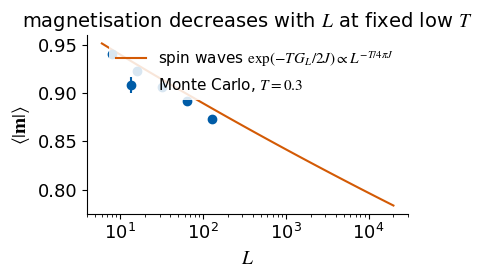

In [18]:
# figure drawn at 4.4 in and placed at 3.3 in on the slide: fonts scaled so that the text appears at about 10.5 pt
SLIDE_FONT = 14
with plt.rc_context({"font.size": SLIDE_FONT, "axes.labelsize": SLIDE_FONT, "axes.titlesize": SLIDE_FONT,
                     "xtick.labelsize": SLIDE_FONT - 1, "ytick.labelsize": SLIDE_FONT - 1, "legend.fontsize": SLIDE_FONT - 3, "mathtext.fontset": "stix", "legend.framealpha": 0.85, "legend.edgecolor": "none"}):
    fig, ax = plt.subplots(figsize=(4.4, 3.0))
    ax.errorbar(L_MW, mw[:, 0], mw[:, 1], fmt="o", color=UJBlue, label=f"Monte Carlo, $T={T_MW}$")
    Lf = np.geomspace(6, 2e4, 100)
    ax.plot(Lf, np.exp(-T_MW / (2 * J) * (np.log(Lf) / (2 * np.pi) + (GL[-1] - np.log(512) / (2 * np.pi)))), color=DSOrange,
            label=r"spin waves $\exp(-T G_L/2J)\propto L^{-T/4\pi J}$")
    ax.set_xscale("log"); ax.set_xlabel("$L$"); ax.set_ylabel(r"$\langle|\mathbf{m}|\rangle$")
    ax.set_title("magnetisation decreases with $L$ at fixed low $T$")
    ax.legend(frameon=True, fontsize=None)
    fig.tight_layout(); savefig(fig, "xy_mermin_wagner.png"); plt.show()

The ratios in the printout stay within about 1% of one, so the Gaussian theory predicts the magnetisation of the finite lattice with no free parameter at $T=0.3$; the small deviation grows slowly with $L$, and the measured exponent is close to $T/(4\pi J_{\rm eff})$. The magnetisation decreases with $L$ as a power law, so it is zero for
$L\to\infty$ (Mermin–Wagner), but so slowly that one would need astronomically large lattices to see it small: with the fitted exponent $x$, halving
$\langle|\boldsymbol m|\rangle$ requires multiplying $L$ by $2^{1/x}$ (printed above).

### 3.4 Spin-wave correlation function

The same calculation gives the spin–spin correlation function at distance $r$,
$$
\begin{aligned}
G(r)&=\langle\cos(\theta_0-\theta_{\boldsymbol r})\rangle=\exp\!\Big(-\tfrac12\langle(\theta_0-\theta_{\boldsymbol r})^2\rangle\Big),\\
\langle(\theta_0-\theta_{\boldsymbol r})^2\rangle&=\frac TJ\,D(\boldsymbol r),\\
D(\boldsymbol r)&=\frac1N\sum_{\boldsymbol k}\frac{2-2\cos(\boldsymbol k\cdot\boldsymbol r)}{\lambda_{\boldsymbol k}} .
\end{aligned}
$$
For $1\ll r\ll L$, $D(r)\approx\frac1\pi\ln r+\text{const}$ (the lattice sum below shows this), hence
$$
G(r)\propto r^{-\eta},\qquad \eta=\frac{T}{2\pi J}.
$$
A **power law**, not an exponential, and not a constant: this is "quasi-long-range order". The exponent $\eta$ depends continuously on $T$:
the whole low-temperature phase is a line of critical points.

In [19]:
L_big = 1024
kk = 2 * np.pi * np.arange(L_big) / L_big
KX, KY = np.meshgrid(kk, kk, indexing="ij")
lam_big = 4 - 2 * np.cos(KX) - 2 * np.cos(KY); lam_big[0, 0] = np.inf
r_list = np.array([2, 4, 8, 16, 32, 64])
D = np.array([((2 - 2 * np.cos(KX * r)) / lam_big).sum() / L_big**2 for r in r_list])     # separation r along x
print(f"lattice sum D(r) on a {L_big} x {L_big} torus")
for i in range(1, len(r_list)):
    print(f"r = {r_list[i-1]:2d} -> {r_list[i]:2d}:  slope dD/d ln r = {(D[i] - D[i-1]) / np.log(2):.5f}")
print(f"1/pi = {1 / np.pi:.5f}")

lattice sum D(r) on a 1024 x 1024 torus
r =  2 ->  4:  slope dD/d ln r = 0.32781
r =  4 ->  8:  slope dD/d ln r = 0.32050
r =  8 -> 16:  slope dD/d ln r = 0.31865
r = 16 -> 32:  slope dD/d ln r = 0.31789
r = 32 -> 64:  slope dD/d ln r = 0.31622
1/pi = 0.31831


<hr/>
## 4. Vortices

The slopes of the lattice sum approach $1/\pi\approx0.318$, which completes the spin-wave picture. So far, however, the Gaussian theory has treated $\theta$ as a real number. But $\theta$ is an angle: going around a closed loop, the angle
may return to its starting value **plus a multiple of $2\pi$**. Such configurations cannot be removed by any small deformation; they are
**topological defects**, and the Gaussian theory misses them entirely. They are what drives the BKT transition.

### 4.1 Winding number

For a closed loop $\mathcal C$ around a point, the **winding number** (vorticity) is
$$
w=\frac1{2\pi}\oint_{\mathcal C}\nabla\theta\cdot d\boldsymbol l\;\in\;\mathbb Z .
$$
A **vortex** is $\theta(\boldsymbol r)=\arctan(y/x)$ (the polar angle, `atan2(y, x)`), with $w=+1$; an **antivortex** $\theta=-\arctan(y/x)$ has $w=-1$.
On the lattice the smallest loop is a plaquette. With the bond angle differences mapped to $[-\pi,\pi)$ (the shortest rotation between two neighbours),
$$
\begin{aligned}
w_p&=\frac1{2\pi}\Big([\theta_2-\theta_1]+[\theta_3-\theta_2]+[\theta_4-\theta_3]+[\theta_1-\theta_4]\Big),\\
[x]&=x \text{ mapped to }[-\pi,\pi),
\end{aligned}
$$
for the corners $1\to2\to3\to4$ traversed counter-clockwise. Without the brackets the sum would be exactly $0$; with them it is $2\pi$ times an
integer. Each bracket lies in $[-\pi,\pi)$, so the sum lies in $[-4\pi,4\pi)$ and $w_p\in\{-2,-1,0,1\}$; the value $-2$ requires all four
brackets to equal $-\pi$ exactly, which has probability zero, so in practice $w_p\in\{-1,0,1\}$.

The sketch below draws the two elementary defects on a $6\times6$ patch, with the core at the centre of a plaquette. Following the spins once counter-clockwise around the dashed contour $\mathcal C$, the arrow turns once counter-clockwise around a vortex ($w=+1$) and once clockwise around an antivortex ($w=-1$). No smooth deformation of the angles can change these integers; a vortex disappears only by meeting an antivortex.

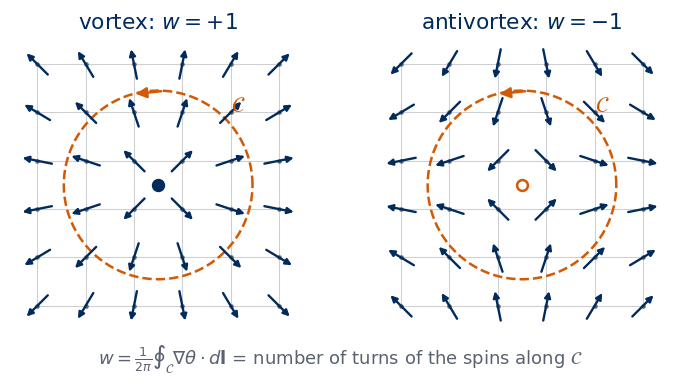

In [20]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_xy_spins(ax, theta, length=0.75, color=NAVY, lw=1.3, head=7, dot=True):
    # planar spins: an arrow of fixed length centred on every lattice site (x, y), angle theta[y, x]
    for (y, x), t in np.ndenumerate(theta):
        dx, dy = 0.5 * length * np.cos(t), 0.5 * length * np.sin(t)
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x - dx, y - dy),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=head, shrinkA=0, shrinkB=0))
        if dot:
            ax.plot(x, y, "o", color=GRAY, ms=1.5, zorder=1)

def plaquette_winding(theta):
    # winding number of every plaquette (lower-left corner (x, y)), corners traversed counter-clockwise
    wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi           # angle difference mapped to [-pi, pi)
    t1, t2 = theta[:-1, :-1], theta[:-1, 1:]                       # (x, y), (x+1, y)
    t3, t4 = theta[1:, 1:], theta[1:, :-1]                         # (x+1, y+1), (x, y+1)
    return np.rint((wrap(t2 - t1) + wrap(t3 - t2) + wrap(t4 - t3) + wrap(t1 - t4)) / (2 * np.pi)).astype(int)

def draw_vortex_marks(ax, w, r=0.3):
    # vortex (w = +1): navy disc with "+";  antivortex (w = -1): white disc with orange rim and "-"
    for (y, x), v in np.ndenumerate(w):
        if v != 0:
            face, edge, txt = (NAVY, NAVY, "white") if v > 0 else ("white", ORANGE, ORANGE)
            ax.add_patch(mpatches.Circle((x + 0.5, y + 0.5), r, fc=face, ec=edge, lw=1.3, zorder=6, alpha=0.9))
            ax.text(x + 0.5, y + 0.5, "+" if v > 0 else "−", color=txt, ha="center", va="center", fontsize=10,
                    fontweight="bold", zorder=7)

def sketch_vortex_antivortex():
    L = 6
    y, x = np.indices((L, L)).astype(float)
    core = (2.5, 2.5)                                               # the core sits at the centre of a plaquette
    fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.9))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.13, top=0.9, wspace=0.08)
    for ax, n, name in [(axes[0], +1, "vortex"), (axes[1], -1, "antivortex")]:
        theta = n * np.arctan2(y - core[1], x - core[0])            # theta = +-(polar angle around the core)
        for k in range(L):
            ax.plot([0, L - 1], [k, k], color=GRAY, lw=0.6, alpha=0.3); ax.plot([k, k], [0, L - 1], color=GRAY, lw=0.6, alpha=0.3)
        draw_xy_spins(ax, theta, length=0.62, lw=1.3, head=7)
        # the closed contour C around the core, traversed counter-clockwise
        phi = np.linspace(0, 2 * np.pi, 200); R = 1.95
        ax.plot(core[0] + R * np.cos(phi), core[1] + R * np.sin(phi), color=ORANGE, lw=1.4, ls="--")
        ax.annotate("", xy=(core[0] + R * np.cos(1.85), core[1] + R * np.sin(1.85)),
                    xytext=(core[0] + R * np.cos(1.5), core[1] + R * np.sin(1.5)),
                    arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.4, mutation_scale=12))
        ax.text(core[0] + R * 0.72 + 0.1, core[1] + R * 0.72 + 0.1, r"$\mathcal{C}$", fontsize=12, color=ORANGE)
        ax.plot(*core, "o", ms=6, color=NAVY if n > 0 else "white", mec=NAVY if n > 0 else ORANGE, mew=1.4, zorder=6)
        ax.set_title(f"{name}: $w={n:+d}$", fontsize=12, color=NAVY)
        ax.set_xlim(-0.5, L - 0.5); ax.set_ylim(-0.5, L - 0.5); ax.set_aspect("equal"); ax.axis("off")
    fig.text(0.5, 0.04, r"$w=\frac{1}{2\pi}\oint_{\mathcal{C}}\nabla\theta\cdot d\mathbf{l}$ = number of turns of the spins along $\mathcal{C}$",
             ha="center", fontsize=10, color=GRAY)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_vortex_antivortex()
save_sketch(fig, "sketch_xy_vortices.png")
plt.show()


SymPy evaluates the contour integral for $\theta=n\,\mathrm{atan2}(y,x)$ on a circle of radius $R$, and also gives $|\nabla\theta|^2$, which we need for the vortex energy.

In [21]:
X, Y, R, t = sp.symbols("x y R t", real=True)
n = sp.symbols("n", integer=True)
theta_v = n * sp.atan2(Y, X)
grad = [sp.simplify(sp.diff(theta_v, X)), sp.simplify(sp.diff(theta_v, Y))]
print("grad theta =", grad)
on_circle = {X: R * sp.cos(t), Y: R * sp.sin(t)}
integrand = sp.simplify((grad[0] * sp.diff(R * sp.cos(t), t) + grad[1] * sp.diff(R * sp.sin(t), t)).subs(on_circle))
print("grad theta . dl/dt on the circle =", integrand)
print("winding number w = (1/2 pi) * contour integral =", sp.integrate(integrand, (t, 0, 2 * sp.pi)) / (2 * sp.pi))
print("|grad theta|^2 =", sp.simplify(grad[0] ** 2 + grad[1] ** 2), "  (= n^2 / r^2)")

grad theta = [-n*y/(x**2 + y**2), n*x/(x**2 + y**2)]
grad theta . dl/dt on the circle = n
winding number w = (1/2 pi) * contour integral = n
|grad theta|^2 = n**2/(x**2 + y**2)   (= n^2 / r^2)


On the lattice we compute the winding numbers of a vortex, an antivortex and a vortex–antivortex pair. Two general properties of `vorticity` are
tested as well: on a torus the total winding number of any configuration is $0$, because every bond is shared by two plaquettes and enters them
with opposite signs, and a smooth configuration (here a spin wave) has no vortices.

In [22]:
Lv = 12
yy, xx = np.meshgrid(np.arange(Lv), np.arange(Lv), indexing="ij")          # yy = row index (y), xx = column index (x)
def vortex_field(x0, y0, w=1):
    # angle of a vortex (w = +1) or antivortex (w = -1) centred at the plaquette centre (x0, y0)
    return w * np.arctan2(yy - y0, xx - x0)
configs = {"vortex": vortex_field(5.5, 5.5, +1),
           "antivortex": vortex_field(5.5, 5.5, -1),
           "pair": vortex_field(3.5, 5.5, +1) + vortex_field(8.5, 5.5, -1)}
for name, th in configs.items():
    w = np.asarray(vorticity(jnp.asarray(th)))
    pos = [(int(c), int(r)) for r, c in zip(*np.nonzero(w > 0))]
    neg = [(int(c), int(r)) for r, c in zip(*np.nonzero(w < 0))]
    print(f"{name:10s}: plaquettes with w=+1 at (x, y) = {pos}, w=-1 at {neg}  (on the torus: sum w = {int(w.sum())})")

theta_sw = 0.4 * np.sin(2 * np.pi * xx / Lv) + 0.3 * np.cos(4 * np.pi * yy / Lv)                       # a smooth spin wave
print(f"spin wave : number of vortices = {int(np.abs(np.asarray(vorticity(jnp.asarray(theta_sw)))).sum())}")
w_rand = np.asarray(vorticity(jax.random.uniform(jax.random.PRNGKey(5), (1000, 32, 32), maxval=TWO_PI)))
print(f"1000 random 32x32 configurations: total winding per configuration ranges from {w_rand.sum((1, 2)).min()} to "
      f"{w_rand.sum((1, 2)).max()};  fraction of plaquettes with w != 0 = {(w_rand != 0).mean():.4f}")

vortex    : plaquettes with w=+1 at (x, y) = [(5, 5), (11, 11)], w=-1 at [(11, 5), (5, 11)]  (on the torus: sum w = 0)
antivortex: plaquettes with w=+1 at (x, y) = [(11, 5), (5, 11)], w=-1 at [(5, 5), (11, 11)]  (on the torus: sum w = 0)
pair      : plaquettes with w=+1 at (x, y) = [(3, 5)], w=-1 at [(8, 5)]  (on the torus: sum w = 0)
spin wave : number of vortices = 0


1000 random 32x32 configurations: total winding per configuration ranges from 0 to 0;  fraction of plaquettes with w != 0 = 0.3331


The pair is placed in the middle of a $12\times12$ open patch; on the torus the field `atan2` has a jump at the boundary, so a single vortex on
the torus comes with an "image" defect at the edge (the printout shows it), consistent with total winding zero.
The vortex density of fully random angles, $\approx 1/3$ of the plaquettes, is the $T\to\infty$ limit of the vortex density measured below.

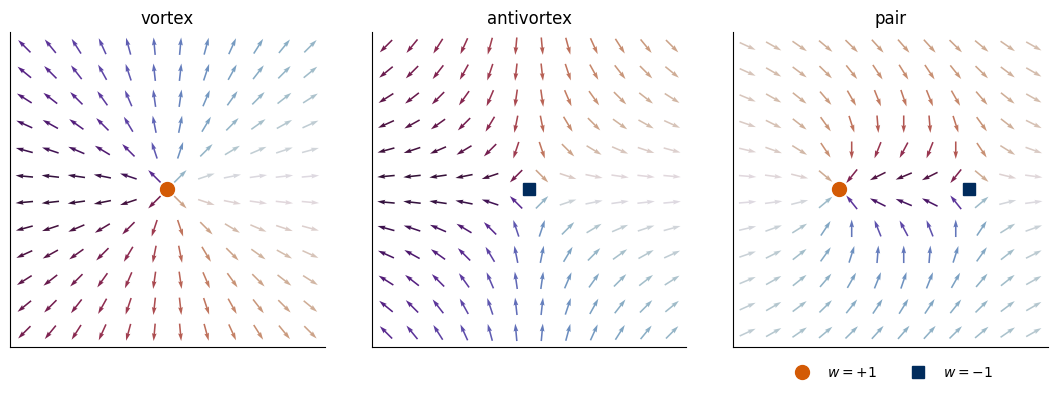

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7))
for ax, (name, th) in zip(axes, configs.items()):
    ax.quiver(xx, yy, np.cos(th), np.sin(th), th % TWO_PI, cmap=ANGLE_CMAP, clim=(0, TWO_PI), pivot="mid", scale=18)
    w = np.asarray(vorticity(jnp.asarray(th)))
    r, c = np.nonzero(w[:-1, :-1] > 0); ax.plot(c + 0.5, r + 0.5, "o", color=DSOrange, ms=10, label="$w=+1$")
    r, c = np.nonzero(w[:-1, :-1] < 0); ax.plot(c + 0.5, r + 0.5, "s", color=UJNavy, ms=9, label="$w=-1$")
    ax.set_title(name); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axes[2].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2)
fig.tight_layout(); savefig(fig, "xy_vortex_configs.png"); plt.show()

### 4.2 Vortex energy

Far from its core a vortex is a smooth configuration, so the Gaussian (continuum) energy applies,
$E-E_0=\frac J2\int d^2r\,|\nabla\theta|^2$. With $|\nabla\theta|^2=1/r^2$ (SymPy above, $n=1$) and the integral running from the core
radius $a$ (the lattice spacing) to the system size $R\approx L$:
$$
E_v=\frac J2\int_a^{R}\frac{1}{r^2}\,2\pi r\,dr+E_{\rm core}=\pi J\ln\frac{R}{a}+E_{\rm core}.
$$
A single vortex costs an energy that **diverges logarithmically** with the system size. A vortex–antivortex pair at distance $d$ is different:
far away ($r\gg d$) the two windings cancel, $\nabla\theta$ decays as $d/r^2$, the integral converges, and
$$
E_{\rm pair}(d)\approx2\pi J\ln\frac da+2E_{\rm core},
$$
independent of $L$. Pairs are cheap, single vortices are not.

In [24]:
r_, a_, R_, Jsym, Tsym = sp.symbols("r a R J T", positive=True)
E_vortex = sp.integrate(Jsym / 2 * (1 / r_**2) * 2 * sp.pi * r_, (r_, a_, R_))
print("E_vortex - E_core =", sp.expand_log(E_vortex, force=True), "  = pi J ln(R/a)")

E_vortex - E_core = pi*J*log(R) - pi*J*log(a)   = pi J ln(R/a)


We check both results on the lattice. We build the vortex `atan2` on an $L\times L$ lattice with **open** boundaries (only the bonds inside the
square count), centred in the middle plaquette, and compute $E_v(L)-E_0(L)$ for $L=8,\dots,512$. The slope against $\ln L$ must approach $\pi J$.
The `atan2` field is the continuum solution; to get the true lattice minimum we also relax the interior with gradient descent (`jax.grad` of the
lattice energy) while keeping the boundary spins fixed, so that the vortex cannot leave. For the pair we place a vortex and an antivortex at
distance $d$ in the middle of a $512\times512$ lattice and check the slope $2\pi J$.

In [25]:
def open_energy(theta):
    # energy of an L x L patch with open boundaries: only bonds inside the patch
    return -J * (jnp.cos(theta[:, 1:] - theta[:, :-1]).sum() + jnp.cos(theta[1:, :] - theta[:-1, :]).sum())

@partial(jax.jit, static_argnames=("n_steps",))
def relax_interior(theta, n_steps, lr=0.2):
    # gradient descent on the interior spins; boundary spins stay fixed
    mask = jnp.zeros_like(theta).at[1:-1, 1:-1].set(1.0)
    g = jax.grad(open_energy)
    return lax.fori_loop(0, n_steps, lambda i, th: th - lr * mask * g(th), theta)

Lv_list = [8, 16, 32, 64, 128, 256, 512]
Ev, Ev_relax = [], []
for L in Lv_list:
    yy_, xx_ = np.meshgrid(np.arange(L), np.arange(L), indexing="ij")
    th = jnp.asarray(np.arctan2(yy_ - (L - 1) / 2, xx_ - (L - 1) / 2))
    E0 = -J * 2 * L * (L - 1)                                               # all spins parallel, 2L(L-1) bonds
    Ev.append(float(open_energy(th)) - E0)
    Ev_relax.append(float(open_energy(relax_interior(th, 3000))) - E0)
Ev, Ev_relax = np.array(Ev), np.array(Ev_relax)
print("   L    E_v - E_0 (atan2)   relaxed     slope vs ln L (atan2, relaxed)")
for i, L in enumerate(Lv_list):
    s = "" if i == 0 else f"{(Ev[i] - Ev[i-1]) / np.log(2):.4f}, {(Ev_relax[i] - Ev_relax[i-1]) / np.log(2):.4f}"
    print(f"{L:4d}   {Ev[i]:10.4f}        {Ev_relax[i]:10.4f}    {s}")
print(f"pi J = {np.pi * J:.4f}")

Lp = 512
yy_, xx_ = np.meshgrid(np.arange(Lp), np.arange(Lp), indexing="ij")
c0 = (Lp - 1) / 2
d_list = np.array([2, 4, 8, 16, 32, 64])
Epair = np.array([float(open_energy(jnp.asarray(np.arctan2(yy_ - c0, xx_ - (c0 - d / 2)) - np.arctan2(yy_ - c0, xx_ - (c0 + d / 2)))))
                  + J * 2 * Lp * (Lp - 1) for d in d_list])
for i in range(1, len(d_list)):
    print(f"pair distance d = {d_list[i-1]:2d} -> {d_list[i]:2d}:  slope dE_pair/d ln d = {(Epair[i] - Epair[i-1]) / np.log(2):.4f}")
print(f"2 pi J = {2 * np.pi * J:.4f}")
NUMBERS.update(vortex_slope_relaxed=round((Ev_relax[-1] - Ev_relax[-2]) / np.log(2), 4))

   L    E_v - E_0 (atan2)   relaxed     slope vs ln L (atan2, relaxed)
   8       8.7257            8.6952    
  16      10.9340           10.9030    3.1859, 3.1851
  32      13.1296           13.0977    3.1677, 3.1663
  64      15.3145           15.2817    3.1520, 3.1510
 128      17.4961           17.4648    3.1474, 3.1496
 256      19.6797           19.6406    3.1503, 3.1390
 512      21.8750           21.8125    3.1672, 3.1334
pi J = 3.1416
pair distance d =  2 ->  4:  slope dE_pair/d ln d = 7.0782
pair distance d =  4 ->  8:  slope dE_pair/d ln d = 6.4921
pair distance d =  8 -> 16:  slope dE_pair/d ln d = 6.4020
pair distance d = 16 -> 32:  slope dE_pair/d ln d = 6.3118
pair distance d = 32 -> 64:  slope dE_pair/d ln d = 6.1765
2 pi J = 6.2832


The single-vortex slope approaches $\pi J$ for both the `atan2` field and the relaxed lattice configuration. The pair slope is close to $2\pi J$
for intermediate distances; at the smallest $d$ the cores overlap, and at the largest $d$ the pair comes close to the open boundary of the
$512\times512$ patch, which lowers the slope.

### 4.3 Kosterlitz–Thouless free-energy argument

The energy alone would forbid single vortices, but the entropy also grows with the system size. The vortex core can sit on any of the
$\approx(L/a)^2$ plaquettes, so $S_v=\ln(L/a)^2=2\ln(L/a)$, and the free energy of one free vortex is (Kosterlitz and Thouless, 1973)
$$
F_v=E_v-TS_v=(\pi J-2T)\ln\frac La+\dots
$$
For $T<\pi J/2$ the coefficient is positive, $F_v\to+\infty$ as $L\to\infty$: free vortices are suppressed and only bound pairs (finite
energy) appear. For $T>\pi J/2$, $F_v\to-\infty$: free vortices proliferate. The estimate of the transition temperature is
$$
T_{\rm KT}^{\rm (estimate)}=\frac{\pi J}{2}\approx1.571\,J .
$$

In [26]:
F_v = (sp.pi * Jsym - 2 * Tsym) * sp.log(sp.Symbol("L", positive=True) / a_)
print("F_v =", F_v)
T_est = sp.solve(sp.Eq(sp.pi * Jsym - 2 * Tsym, 0), Tsym)[0]
print("coefficient of ln(L/a) vanishes at T =", T_est, "=", float(T_est.subs(Jsym, 1)), "J")
print(f"literature value T_BKT = {T_BKT_LIT:.4f} J;  ratio estimate / literature = {np.pi / 2 / T_BKT_LIT:.3f}")

F_v = (pi*J - 2*T)*log(L/a)
coefficient of ln(L/a) vanishes at T = pi*J/2 = 1.5707963267948966 J
literature value T_BKT = 0.8929 J;  ratio estimate / literature = 1.759


The estimate is **too high** by about 76% (the ratio $1.759$ printed above). The reason is physical: below $T_{\rm BKT}$ the system is full of thermally excited bound pairs,
which act like a polarisable medium (dipoles in a dielectric) and **screen** the interaction, so that a free vortex costs
$\pi\Upsilon\ln(L/a)$ with a reduced, renormalised stiffness $\Upsilon<J$ instead of $\pi J\ln(L/a)$. Replacing $J$ by $\Upsilon$ in the argument gives
the self-consistency condition $\Upsilon(T_{\rm BKT})=2T_{\rm BKT}/\pi$ — exactly the Nelson–Kosterlitz universal jump of Section 5, derived
properly with the renormalisation group by Kosterlitz (1974) and Nelson and Kosterlitz (1977).

The sketch below contrasts the two situations of the argument. On the left, a vortex and an antivortex sit two lattice spacings apart; far from the pair their windings cancel and the spins are almost parallel, so the pair costs a finite energy and occurs at low temperature. On the right, vortices and antivortices are far apart from each other; each twists the spins over a large region, and such free vortices appear only above the transition, where their entropy wins. The discs mark the plaquettes with winding number $w_p=+1$ (navy, "+") and $w_p=-1$ (white with an orange rim, "−"), computed from the arrows with the formula of Section 4.1; the sketches follow the course convention, while the snapshot figure below uses its own markers.

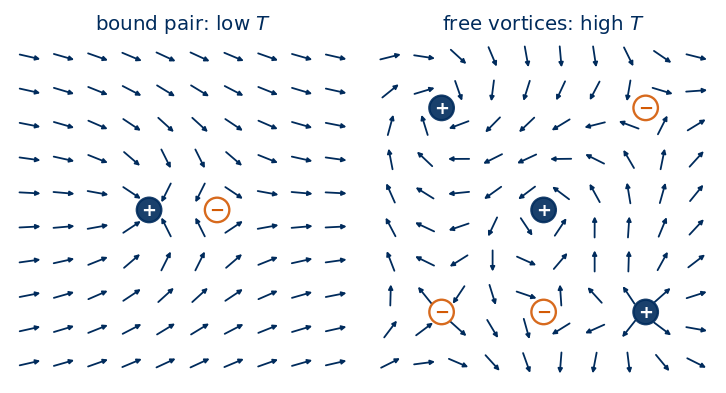

In [27]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_xy_spins(ax, theta, length=0.75, color=NAVY, lw=1.3, head=7, dot=True):
    # planar spins: an arrow of fixed length centred on every lattice site (x, y), angle theta[y, x]
    for (y, x), t in np.ndenumerate(theta):
        dx, dy = 0.5 * length * np.cos(t), 0.5 * length * np.sin(t)
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x - dx, y - dy),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=head, shrinkA=0, shrinkB=0))
        if dot:
            ax.plot(x, y, "o", color=GRAY, ms=1.5, zorder=1)

def plaquette_winding(theta):
    # winding number of every plaquette (lower-left corner (x, y)), corners traversed counter-clockwise
    wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi           # angle difference mapped to [-pi, pi)
    t1, t2 = theta[:-1, :-1], theta[:-1, 1:]                       # (x, y), (x+1, y)
    t3, t4 = theta[1:, 1:], theta[1:, :-1]                         # (x+1, y+1), (x, y+1)
    return np.rint((wrap(t2 - t1) + wrap(t3 - t2) + wrap(t4 - t3) + wrap(t1 - t4)) / (2 * np.pi)).astype(int)

def draw_vortex_marks(ax, w, r=0.3):
    # vortex (w = +1): navy disc with "+";  antivortex (w = -1): white disc with orange rim and "-"
    for (y, x), v in np.ndenumerate(w):
        if v != 0:
            face, edge, txt = (NAVY, NAVY, "white") if v > 0 else ("white", ORANGE, ORANGE)
            ax.add_patch(mpatches.Circle((x + 0.5, y + 0.5), r, fc=face, ec=edge, lw=1.3, zorder=6, alpha=0.9))
            ax.text(x + 0.5, y + 0.5, "+" if v > 0 else "−", color=txt, ha="center", va="center", fontsize=10,
                    fontweight="bold", zorder=7)

def sketch_bound_and_free_vortices():
    L = 10
    y, x = np.indices((L, L)).astype(float)
    def field(defects):
        # superposition of vortices (q = +1) and antivortices (q = -1) at plaquette centres (cx, cy)
        return sum(q * np.arctan2(y - cy, x - cx) for (cx, cy, q) in defects)
    panels = [([(3.5, 4.5, +1), (5.5, 4.5, -1)], "bound pair: low $T$"),
              ([(1.5, 7.5, +1), (7.5, 7.5, -1), (4.5, 4.5, +1), (1.5, 1.5, -1), (7.5, 1.5, +1), (4.5, 1.5, -1)],
               "free vortices: high $T$")]
    fig, axes = plt.subplots(1, 2, figsize=(5.5, 3.0))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.9, wspace=0.06)
    for ax, (defects, title) in zip(axes, panels):
        theta = field(defects)
        draw_xy_spins(ax, theta, length=0.62, lw=1.0, head=5, dot=False)
        draw_vortex_marks(ax, plaquette_winding(theta), r=0.36)      # winding numbers computed on every plaquette
        ax.set_title(title, fontsize=11, color=NAVY)
        ax.set_xlim(-0.5, L - 0.5); ax.set_ylim(-0.5, L - 0.5); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_bound_and_free_vortices()
save_sketch(fig, "sketch_xy_vortex_pairs.png")
plt.show()


### 4.4 Vortices in Monte Carlo snapshots

To see the defects we look at snapshots from the data set ($L=48$) at three temperatures, below, near and above $T_{\rm BKT}$. In the figure, colour is the angle (cyclic colour map), orange circles are vortices, navy squares antivortices.

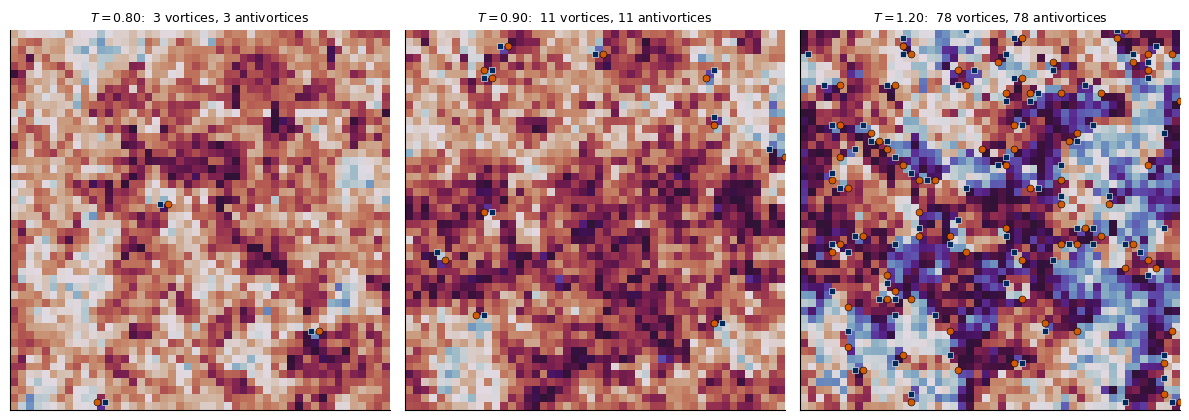

In [28]:
L = 48
T_show = [0.80, 0.90, 1.20]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, T in zip(axes, T_show):
    i = int(np.argmin(abs(T_GRID - T)))
    th = DS[L]["theta"][i, 0]
    w = np.asarray(vorticity(jnp.asarray(th)))
    ax.imshow(th, cmap=ANGLE_CMAP, vmin=0, vmax=TWO_PI, origin="lower")
    r, c = np.nonzero(w > 0); ax.plot(c + 0.5, r + 0.5, "o", color=DSOrange, ms=5, mec="k", mew=0.4)
    r, c = np.nonzero(w < 0); ax.plot(c + 0.5, r + 0.5, "s", color=UJNavy, ms=4.5, mec="w", mew=0.4)
    ax.set_title(f"$T={T_GRID[i]:.2f}$:  {int((w > 0).sum())} vortices, {int((w < 0).sum())} antivortices", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlim(-0.5, L - 0.5); ax.set_ylim(-0.5, L - 0.5)
fig.tight_layout(); savefig(fig, "xy_snapshots_vortices.png"); plt.show()

At $T=0.80$ each of the three vortices sits on a plaquette next to an antivortex. At $T=0.90\approx T_{\rm BKT}$ there are more defects,
still in tightly bound vortex–antivortex pairs. At $T=1.20$ the defects are numerous and many of them have no partner on a neighbouring
plaquette: the angle field is disordered.

To quantify this we measure the vortex density $n_v$, the number of plaquettes with $w\neq0$ per site, averaged over all measurement steps.
At low $T$ bound pairs are thermally activated, $n_v\propto e^{-E_a/T}$, with an activation energy $E_a$. We fit $E_a$ on the low-temperature part ($T\le0.75$, $L=48$).

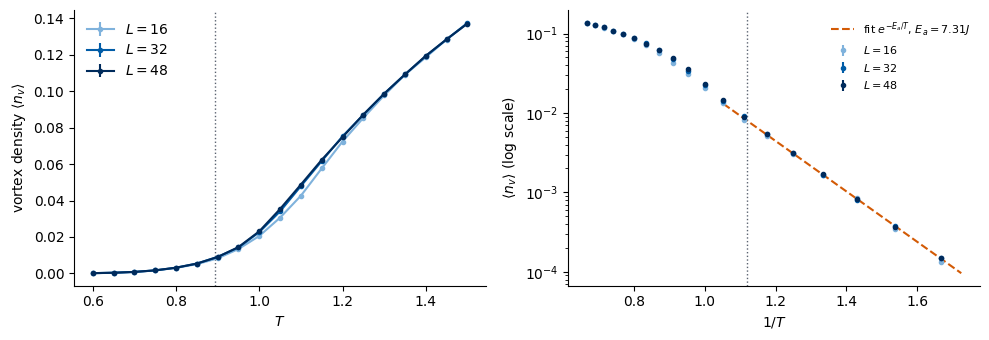

L = 16: <n_v>(T = 0.70) = 0.00085,  <n_v>(T = 0.90) = 0.0083,  <n_v>(T = 1.50) = 0.1372
L = 32: <n_v>(T = 0.70) = 0.00081,  <n_v>(T = 0.90) = 0.0091,  <n_v>(T = 1.50) = 0.1375
L = 48: <n_v>(T = 0.70) = 0.00082,  <n_v>(T = 0.90) = 0.0090,  <n_v>(T = 1.50) = 0.1372
fitted activation energy (L = 48, T <= 0.75): E_a = 7.314 J


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for L in L_LIST:
    ax[0].errorbar(T_GRID, TH[L]["nv"][:, 0], TH[L]["nv"][:, 1], fmt="o-", ms=3, color=L_COLORS[L], label=f"$L={L}$")
    ax[1].errorbar(1 / T_GRID, TH[L]["nv"][:, 0], TH[L]["nv"][:, 1], fmt="o", ms=3, color=L_COLORS[L], label=f"$L={L}$")
low = T_GRID <= 0.75
slope, icpt = np.polyfit(1 / T_GRID[low], np.log(TH[48]["nv"][low, 0]), 1)
xf = np.linspace(1 / 0.95, 1 / 0.58, 50)
ax[1].plot(xf, np.exp(icpt + slope * xf), "--", color=DSOrange, label=f"fit $e^{{-E_a/T}}$, $E_a={-slope:.2f}J$")
for a in ax:
    a.axvline(T_BKT_LIT if a is ax[0] else 1 / T_BKT_LIT, color=UJGray, ls=":", lw=1)
ax[0].set_xlabel("$T$"); ax[0].set_ylabel(r"vortex density $\langle n_v\rangle$")
ax[1].set_yscale("log"); ax[1].set_xlabel("$1/T$"); ax[1].set_ylabel(r"$\langle n_v\rangle$ (log scale)")
ax[0].legend(frameon=False); ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "xy_vortex_density.png"); plt.show()
iB = int(np.argmin(abs(T_GRID - 0.90)))
for L in L_LIST:
    print(f"L = {L}: <n_v>(T = 0.70) = {TH[L]['nv'][2, 0]:.5f},  <n_v>(T = {T_GRID[iB]:.2f}) = {TH[L]['nv'][iB, 0]:.4f},  "
          f"<n_v>(T = 1.50) = {TH[L]['nv'][-1, 0]:.4f}")
print(f"fitted activation energy (L = 48, T <= 0.75): E_a = {-slope:.3f} J")
NUMBERS.update(nv_T090_L48=round(float(TH[48]["nv"][iB, 0]), 4), nv_Ea=round(-slope, 3))

The vortex density is essentially **independent of $L$** and **smooth** in $T$: it rises steeply around and above $T_{\rm BKT}$ but shows no
feature at $T_{\rm BKT}$ itself. The density counts bound pairs and free vortices alike; the transition is about whether they are **bound**,
which a density cannot tell. This matters for Section 8.
At low $T$ the density is activated, with the fitted activation energy $E_a\approx7.3J$: bound pairs are rare but always present at $T>0$.

<hr/>
## 5. Helicity modulus (spin stiffness)

Neither $\langle|\boldsymbol m|\rangle$ (zero for $L\to\infty$) nor the vortex density (smooth) distinguishes the two phases.
The quantity that does is the **response to a twist**. In the low-temperature phase the spins resist being twisted, as a solid resists shear or a superfluid resists a
phase gradient (superfluid density); in the high-temperature phase free vortices relax any twist and the resistance vanishes.

### 5.1 Definition and estimator

Impose a total twist $\Delta$ of the angle across the system in the $x$ direction, spread evenly over the $L$ columns: replace every
horizontal bond angle $\theta_{r+\hat x}-\theta_r$ by $\theta_{r+\hat x}-\theta_r-\alpha$ with $\alpha=\Delta/L$. The **helicity modulus**
$\Upsilon$ is defined by the increase of the free energy,
$$
\begin{aligned}
F(\Delta)-F(0)&=\frac{\Upsilon}{2}\,\Delta^2+O(\Delta^4)\quad\text{(in two dimensions)},\quad\text{i.e.}\\
\Upsilon&=\frac{\partial^2F}{\partial\Delta^2}\Big|_0=\frac1{L^2}\frac{\partial^2F}{\partial\alpha^2}\Big|_0 .
\end{aligned}
$$

The sketch below shows the twist at low temperature. A total twist $\Delta$ means that the right neighbour of the last column is the first column turned by $\Delta$ (orange arrows). The spins respond by turning gradually, by $\alpha=\Delta/L$ from one column to the next, so each horizontal bond costs about $\frac J2\alpha^2$. At $T=0$ the $L^2$ horizontal bonds give $F(\Delta)-F(0)=\frac J2\Delta^2$, that is $\Upsilon=J$. At high temperature free vortices can unwind the twist, and then $\Upsilon=0$.

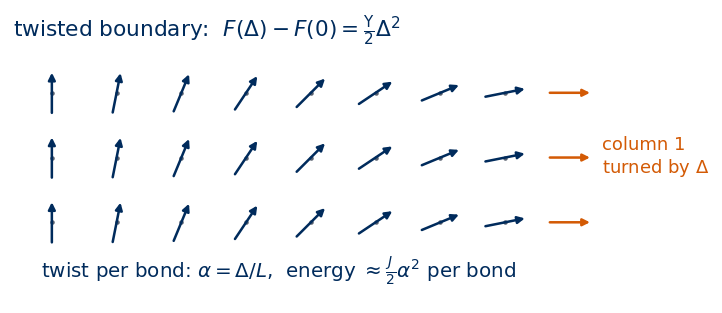

In [30]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_xy_spins(ax, theta, length=0.75, color=NAVY, lw=1.3, head=7, dot=True):
    # planar spins: an arrow of fixed length centred on every lattice site (x, y), angle theta[y, x]
    for (y, x), t in np.ndenumerate(theta):
        dx, dy = 0.5 * length * np.cos(t), 0.5 * length * np.sin(t)
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x - dx, y - dy),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=head, shrinkA=0, shrinkB=0))
        if dot:
            ax.plot(x, y, "o", color=GRAY, ms=1.5, zorder=1)

def plaquette_winding(theta):
    # winding number of every plaquette (lower-left corner (x, y)), corners traversed counter-clockwise
    wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi           # angle difference mapped to [-pi, pi)
    t1, t2 = theta[:-1, :-1], theta[:-1, 1:]                       # (x, y), (x+1, y)
    t3, t4 = theta[1:, 1:], theta[1:, :-1]                         # (x+1, y+1), (x, y+1)
    return np.rint((wrap(t2 - t1) + wrap(t3 - t2) + wrap(t4 - t3) + wrap(t1 - t4)) / (2 * np.pi)).astype(int)

def draw_vortex_marks(ax, w, r=0.3):
    # vortex (w = +1): navy disc with "+";  antivortex (w = -1): white disc with orange rim and "-"
    for (y, x), v in np.ndenumerate(w):
        if v != 0:
            face, edge, txt = (NAVY, NAVY, "white") if v > 0 else ("white", ORANGE, ORANGE)
            ax.add_patch(mpatches.Circle((x + 0.5, y + 0.5), r, fc=face, ec=edge, lw=1.3, zorder=6, alpha=0.9))
            ax.text(x + 0.5, y + 0.5, "+" if v > 0 else "−", color=txt, ha="center", va="center", fontsize=10,
                    fontweight="bold", zorder=7)

def sketch_twisted_boundary():
    L, ny = 8, 3
    Delta = np.pi / 2                                               # total twist imposed across the system
    alpha = Delta / L                                               # twist per horizontal bond
    fig = plt.figure(figsize=(5.5, 2.4))
    ax = fig.add_axes([0.02, 0.0, 0.96, 0.86])
    # lowest-energy state with the twist: the angle turns by alpha from one column to the next,
    # so that the right neighbour of the last column is column 1 turned by Delta
    theta = np.tile(np.pi / 2 - alpha * np.arange(L + 1), (ny, 1))
    draw_xy_spins(ax, theta[:, :L], length=0.62, lw=1.4, head=8)
    for yy in range(ny):                                            # the periodic copy of column 1, turned by Delta
        t = theta[yy, L]
        ax.annotate("", xy=(L + 0.31 * np.cos(t), yy + 0.31 * np.sin(t)), xytext=(L - 0.31 * np.cos(t), yy - 0.31 * np.sin(t)),
                    arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.4, mutation_scale=8, shrinkA=0, shrinkB=0))
    ax.text(L + 0.5, 1.0, "column 1\nturned by $\\Delta$", fontsize=10, color=ORANGE, va="center")
    ax.text(3.5, -0.85, r"twist per bond: $\alpha=\Delta/L$,  energy $\approx\frac{J}{2}\alpha^2$ per bond", ha="center", fontsize=11, color=NAVY)
    ax.set_title(r"twisted boundary:  $F(\Delta)-F(0)=\frac{\Upsilon}{2}\Delta^2$", fontsize=12, color=NAVY, loc="left")
    ax.set_xlim(-0.6, L + 2.0); ax.set_ylim(-1.2, ny - 0.3); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_twisted_boundary()
save_sketch(fig, "sketch_xy_twist.png")
plt.show()


(In the continuum, $F=\frac\Upsilon2\int d^2r\,(\nabla\theta)^2$ with $\nabla\theta=\Delta/L$ gives the same $\frac\Upsilon2\Delta^2$: $\Upsilon$ is the
renormalised, effective $J$ at long wavelengths.) With $F=-T\ln Z(\alpha)$ and
$H(\alpha)=-J\sum_{\rm x\ bonds}\cos(\Delta^x_r-\alpha)-J\sum_{\rm y\ bonds}\cos\Delta^y_r$, two derivatives give
$$
\begin{aligned}
\frac{\partial^2F}{\partial\alpha^2}\Big|_0&=\Big\langle\frac{\partial^2H}{\partial\alpha^2}\Big\rangle-\beta\Big(\Big\langle\Big(\frac{\partial H}{\partial\alpha}\Big)^2\Big\rangle-\Big\langle\frac{\partial H}{\partial\alpha}\Big\rangle^2\Big)\\
&=J\langle C_x\rangle-\beta J^2\big(\langle S_x^2\rangle-\langle S_x\rangle^2\big),
\end{aligned}
$$
with $C_x=\sum\cos\Delta^x_r$ and $S_x=\sum\sin\Delta^x_r$ as measured in Section 2. By symmetry $\langle S_x\rangle=0$, and averaging the $x$ and $y$ directions,
$$
\boxed{\;\Upsilon=\frac{1}{2N}\Big[J\langle C_x+C_y\rangle-\beta J^2\langle S_x^2+S_y^2\rangle\Big]\;}
$$
The first term is (minus) the energy per bond; the second is the fluctuation of the total "spin current".

The derivative identity can be checked symbolically on a toy system with three configurations and two twisted bonds each: SymPy computes
$\partial_\alpha^2(-T\ln Z)$ and compares it with the right-hand side.

In [31]:
al, bt, Js = sp.symbols("alpha beta J", positive=True)
d = sp.symbols("d0:6", real=True)                        # bond angles: configuration c has bonds d[2c], d[2c+1]
Hc = [-Js * (sp.cos(d[2 * c] - al) + sp.cos(d[2 * c + 1] - al)) for c in range(3)]
Z = sum(sp.exp(-bt * h) for h in Hc)
F2 = sp.diff(-sp.log(Z) / bt, al, 2).subs(al, 0)
w_ = [sp.exp(-bt * h.subs(al, 0)) / Z.subs(al, 0) for h in Hc]
Cc = [sp.cos(d[2 * c]) + sp.cos(d[2 * c + 1]) for c in range(3)]
Sc = [sp.sin(d[2 * c]) + sp.sin(d[2 * c + 1]) for c in range(3)]
avg = lambda q: sum(wi * qi for wi, qi in zip(w_, q))
estimator = Js * avg(Cc) - bt * Js**2 * (avg([s**2 for s in Sc]) - avg(Sc) ** 2)
print("d^2F/d alpha^2 - [J<C> - beta J^2 (<S^2> - <S>^2)] simplifies to:", sp.simplify(F2 - estimator))

d^2F/d alpha^2 - [J<C> - beta J^2 (<S^2> - <S>^2)] simplifies to: 0


### 5.2 Low-temperature stiffness

In the Gaussian theory each bond angle has $\langle(\Delta^x)^2\rangle=T/(2J)$ (equipartition: $N$ modes $\times\,T/2$ shared by $2N$ bonds, each
with energy $\frac J2(\Delta)^2$), so $\langle\cos\Delta^x\rangle\approx1-\frac T{4J}$. The current term vanishes at this order: with periodic
boundaries the sum of $\Delta^x$ along each row is exactly zero, so $S_x=\sum\sin\Delta^x\approx\sum\Delta^x=0$. Therefore
$$
\Upsilon\approx J-\frac T4+O(T^2).
$$
This is the anharmonic stiffness used in Section 3.3. Below we compare with the Monte Carlo data at the lowest temperatures, and run two extra
temperatures, $T=0.1$ and $0.3$.

In [32]:
Tq = sp.symbols("T", positive=True)
print("<cos Delta> to first order with <Delta^2> = T/(2J):", sp.series(sp.exp(-Tq / (2 * Js) / 2), Tq, 0, 2), " (Gaussian: <cos> = exp(-<Delta^2>/2))")

ser, _ = run_chains(32, [0.1, 0.3], n_chains=32, n_equil=1000, n_meas=2000, n_store=1, n_or=1, seed=20)
for i, T in enumerate([0.1, 0.3]):
    cm = chain_moments(ser[i])
    u, du = jackknife(lambda v: helicity_from_means(v[[2, 3]], 1 / T, 32 * 32), cm)
    print(f"L = 32, T = {T}:  Upsilon_MC = {u:.4f} +- {du:.1e}   J - T/4 = {J - T / 4:.4f}")
for i in (0, 1, 2):
    print(f"L = 48, T = {T_GRID[i]:.2f}:  Upsilon_MC = {TH[48]['ups'][i, 0]:.4f} +- {TH[48]['ups'][i, 1]:.1e}   J - T/4 = {J - T_GRID[i] / 4:.4f}")

<cos Delta> to first order with <Delta^2> = T/(2J): -T/(4*J) + 1 + O(T**2)  (Gaussian: <cos> = exp(-<Delta^2>/2))


L = 32, T = 0.1:  Upsilon_MC = 0.9745 +- 9.4e-06   J - T/4 = 0.9750
L = 32, T = 0.3:  Upsilon_MC = 0.9195 +- 3.0e-05   J - T/4 = 0.9250
L = 48, T = 0.60:  Upsilon_MC = 0.8200 +- 1.6e-04   J - T/4 = 0.8500
L = 48, T = 0.65:  Upsilon_MC = 0.7997 +- 2.1e-04   J - T/4 = 0.8375
L = 48, T = 0.70:  Upsilon_MC = 0.7771 +- 2.7e-04   J - T/4 = 0.8250


At $T=0.1$ and $0.3$ the deviation from $J-T/4$ is of order $T^2$. From $T=0.6$ on the stiffness falls clearly below the linear law:
higher-order anharmonic terms and bound vortex pairs, both absent from the Gaussian theory, reduce it.

### 5.3 Universal jump

Nelson and Kosterlitz (1977) showed with the renormalisation group that in the thermodynamic limit the stiffness jumps from a **universal**
value to zero:
$$
\lim_{T\to T_{\rm BKT}^-}\Upsilon(T)=\frac{2}{\pi}\,T_{\rm BKT},\qquad \Upsilon(T)=0\ \text{ for }T>T_{\rm BKT}.
$$
This is the self-consistent version of the free-energy argument of Section 4.3 (a free vortex costs $\pi\Upsilon\ln L$ and gains $2T\ln L$).
For superfluid films $\Upsilon$ is proportional to the superfluid density, hence the title of their paper.

On a finite lattice $\Upsilon_L(T)$ is smooth and positive at all $T$; it decreases with $L$ above $T_{\rm BKT}$ and the drop sharpens.
This suggests the **crossing method**: define $T^*(L)$ as the temperature where $\Upsilon_L(T)$ crosses the line $2T/\pi$; as $L\to\infty$, $T^*(L)\to T_{\rm BKT}$.

The approach to the limit is slow. Above $T_{\rm BKT}$ the correlation length diverges as (Kosterlitz 1974)
$\xi\propto\exp\!\big(b/\sqrt{T-T_{\rm BKT}}\big)$, with a non-universal constant $b$. The finite lattice "looks critical" as long as
$\xi\gtrsim L$; setting $\xi=L$ gives
$$
T^*(L)-T_{\rm BKT}\simeq\frac{b^2}{(\ln L)^2},
$$
a very slow, logarithmic approach. We fit this form to our three sizes; with only $L=16,32,48$ the extrapolation is rough.

In [33]:
tt, bb, Ls_ = sp.symbols("t b L", positive=True)
print("solve exp(b / sqrt(t)) = L for t:", sp.solve(sp.Eq(sp.exp(bb / sp.sqrt(tt)), Ls_), tt))

def crossing(T, ups):
    # temperature where ups(T) - 2T/pi changes sign, by linear interpolation between grid points
    f = ups - 2 * T / np.pi
    i = np.nonzero((f[:-1] > 0) & (f[1:] <= 0))[0][0]
    return T[i] - f[i] * (T[i + 1] - T[i]) / (f[i + 1] - f[i])

def ups_curve(cm_all, L):
    # cm_all: (nT, k) pooled moments -> Upsilon(T) on the grid
    return np.array([helicity_from_means(cm_all[i, [2, 3]], 1 / T_GRID[i], L * L) for i in range(len(T_GRID))])

T_cross = {}
for L in L_LIST:
    cm = DS[L]["chain_moments"]                                      # (nT, n_chains, 9)
    n = cm.shape[1]
    full = crossing(T_GRID, ups_curve(cm.mean(1), L))
    loo = np.array([crossing(T_GRID, ups_curve((cm.sum(1) - cm[:, j]) / (n - 1), L)) for j in range(n)])
    T_cross[L] = (full, np.sqrt((n - 1) / n * ((loo - loo.mean()) ** 2).sum()))
    print(f"L = {L}:  T*(L) = {T_cross[L][0]:.4f} +- {T_cross[L][1]:.4f}")

Lc = np.array(L_LIST, float)
Tc_ = np.array([T_cross[L][0] for L in L_LIST]); dTc_ = np.array([T_cross[L][1] for L in L_LIST])
popt, pcov = curve_fit(lambda L, Tb, b2: Tb + b2 / np.log(L) ** 2, Lc, Tc_, sigma=dTc_, absolute_sigma=True, p0=(0.9, 1.0))
T_BKT_fit, dT_BKT_fit = popt[0], np.sqrt(pcov[0, 0])
print(f"extrapolation T*(L) = T_BKT + b^2/(ln L)^2:  T_BKT = {T_BKT_fit:.3f} +- {dT_BKT_fit:.3f},  b^2 = {popt[1]:.3f}")
print(f"literature (Hasenbusch 2005): T_BKT = {T_BKT_LIT:.4f}")
NUMBERS.update({f"Tstar_L{L}": round(float(T_cross[L][0]), 4) for L in L_LIST})
NUMBERS.update(T_BKT_extrapolated=round(float(T_BKT_fit), 3), T_BKT_extrapolated_err=round(float(dT_BKT_fit), 3), T_BKT_literature=round(T_BKT_LIT, 4))

solve exp(b / sqrt(t)) = L for t: [b**2/log(L)**2]
L = 16:  T*(L) = 0.9357 +- 0.0022
L = 32:  T*(L) = 0.9211 +- 0.0020
L = 48:  T*(L) = 0.9170 +- 0.0011
extrapolation T*(L) = T_BKT + b^2/(ln L)^2:  T_BKT = 0.897 +- 0.003,  b^2 = 0.294
literature (Hasenbusch 2005): T_BKT = 0.8929


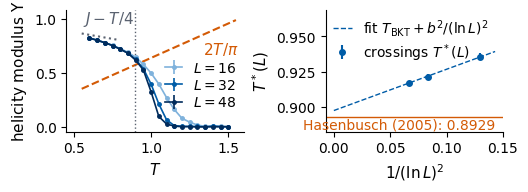

In [34]:
# figure drawn at its size on the slide (5.5 in = text width) with 10-11 pt text; the two reference lines are labelled
# directly and the legends sit in empty corners, so that no text covers the data
with plt.rc_context({"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 10, "lines.linewidth": 1.5}):
    fig, ax = plt.subplots(1, 2, figsize=(5.5, 2.05))
    for L in L_LIST:
        ax[0].errorbar(T_GRID, TH[L]["ups"][:, 0], TH[L]["ups"][:, 1], fmt="o-", ms=2.5, lw=1.2, color=L_COLORS[L], label=f"$L={L}$")
    Tf = np.linspace(0.55, 1.55, 100)
    ax[0].plot(Tf, 2 * Tf / np.pi, "--", color=DSOrange)
    ax[0].plot(Tf[Tf < 0.8], J - Tf[Tf < 0.8] / 4, ":", color=UJGray)
    ax[0].text(1.57, 2 * 1.57 / np.pi - 0.2, r"$2T/\pi$", color=DSOrange, ha="right", va="top")
    ax[0].text(0.56, J - 0.56 / 4 + 0.05, r"$J-T/4$", color=UJGray, ha="left", va="bottom")
    ax[0].axvline(T_BKT_LIT, color=UJGray, ls=":", lw=1)
    ax[0].set_xlim(0.45, 1.6); ax[0].set_ylim(-0.05, 1.08)
    ax[0].set_xlabel("$T$"); ax[0].set_ylabel(r"helicity modulus $\Upsilon$")
    ax[0].legend(frameon=False, loc="upper right", bbox_to_anchor=(1.0, 0.64), handlelength=1.2, borderaxespad=0.1, labelspacing=0.25)
    x_ = 1 / np.log(Lc) ** 2
    ax[1].errorbar(x_, Tc_, dTc_, fmt="o", ms=4, color=UJBlue, label=r"crossings $T^*(L)$")
    xf = np.linspace(0, x_.max() * 1.1, 50)
    ax[1].plot(xf, T_BKT_fit + popt[1] * xf, "--", color=UJBlue, lw=1, label=r"fit $T_{\rm BKT}+b^2/(\ln L)^2$")
    ax[1].axhline(T_BKT_LIT, color=DSOrange, lw=1)
    ax[1].text(xf.max(), T_BKT_LIT - 0.0012, f"Hasenbusch (2005): {T_BKT_LIT:.4f}", color=DSOrange, ha="right", va="top", fontsize=10)
    lo = T_BKT_LIT - 0.011; hi = max(Tc_ + dTc_) + 0.004
    ax[1].set_ylim(lo, hi + 0.45 * (hi - lo))                     # head room for the legend above the data
    ax[1].set_xlabel(r"$1/(\ln L)^2$"); ax[1].set_ylabel(r"$T^*(L)$")
    ax[1].legend(frameon=False, loc="upper left", handlelength=1.4, borderaxespad=0.1, labelspacing=0.25)
    fig.tight_layout(w_pad=1.0); savefig(fig, "xy_helicity_modulus.png"); plt.show()

In the figure, $\Upsilon_L(T)$ is close to $J-T/4$ at low $T$, bends down near $T_{\rm BKT}$, and above it decreases with $L$ — the finite-size
image of the jump to zero. The crossings $T^*(L)$ with $2T/\pi$ lie above $T_{\rm BKT}$ and move down as $L$ grows; the logarithmic extrapolation
from three sizes gives a value within about 0.005 of the high-precision result of Hasenbusch (2005) (printed above). The quoted error is only
statistical: with three sizes and two fit parameters the systematic uncertainty of the extrapolation form is not controlled. Precision
studies use much larger lattices and the full renormalisation-group form of the finite-size corrections.

<hr/>
## 6. Correlation function

The spin-wave theory (Section 3.4) predicts $G(r)\propto r^{-\eta(T)}$ with $\eta=T/(2\pi J)$ at low $T$. Vortices modify this in two
ways: below $T_{\rm BKT}$ bound pairs renormalise $J\to\Upsilon$, so $\eta(T)=T/(2\pi\Upsilon(T))$; at $T_{\rm BKT}$ the universal jump
gives
$$
\eta(T_{\rm BKT})=\frac{T_{\rm BKT}}{2\pi\cdot2T_{\rm BKT}/\pi}=\frac14
$$
(Kosterlitz 1974). Above $T_{\rm BKT}$ free vortices randomise the angle beyond a distance $\xi$, and $G(r)\propto e^{-r/\xi}$.

To measure the correlation function we use, for each snapshot, $G(\boldsymbol r)=\frac1N\sum_i\cos(\theta_i-\theta_{i+\boldsymbol r})$, the real part of the circular
autocorrelation of $z_i=e^{i\theta_i}$, computed with fast Fourier transforms (FFT): $G=\mathrm{Re}\,\mathrm{IFFT}(|\mathrm{FFT}(z)|^2)/N$.
We average over snapshots and over the two lattice directions, $r=0,\dots,L/2$.

Two tests follow. Below $T_{\rm BKT}$ we test renormalised spin waves: on the same $48\times48$ torus the Gaussian theory with $J$ replaced by the measured
stiffness $\Upsilon$ predicts, with no free parameter,
$$
\begin{aligned}
G_{\rm SW}(r)&=\exp\!\Big(-\frac{T}{2\Upsilon}\,D_L(r)\Big),\\
D_L(r)&=\frac1N\sum_{\boldsymbol k\neq0}\frac{2-2\cos k_xr}{\lambda_{\boldsymbol k}},
\end{aligned}
$$
which contains the periodic images automatically. A direct power-law fit $G\propto r^{-\eta}$ is unreliable on a lattice this small: the
image at distance $L-r$ and the short-distance corrections bend the curve on the log–log plot over the whole range $r\le L/2$. Above $T_{\rm BKT}$ we test exponential decay and fit $G(r)=A\big[e^{-r/\xi}+e^{-(L-r)/\xi}\big]$ (with the periodic image) for $r\ge2$.

In [35]:
print("eta at the universal jump:", sp.simplify(Tsym / (2 * sp.pi * (2 * Tsym / sp.pi))))

def correlation(theta):
    # theta: (n, L, L) -> G(r), r = 0..L/2, averaged over samples and the x and y directions
    L = theta.shape[-1]
    z = np.exp(1j * theta.astype(np.float64))
    Fz = np.fft.fft2(z)
    G2d = np.fft.ifft2(np.abs(Fz) ** 2).real.mean(0) / (L * L)          # (L, L), G2d[dy, dx]
    return 0.5 * (G2d[0, : L // 2 + 1] + G2d[: L // 2 + 1, 0])

def D_torus(L):
    # D_L(r) = (1/N) sum_{k != 0} (2 - 2 cos k_x r) / lambda_k on the L x L torus, r = 0..L/2
    kk = 2 * np.pi * np.arange(L) / L
    KX, KY = np.meshgrid(kk, kk, indexing="ij")
    lam = 4 - 2 * np.cos(KX) - 2 * np.cos(KY); lam[0, 0] = np.inf
    return np.array([((2 - 2 * np.cos(KX * r)) / lam).sum() / L**2 for r in range(L // 2 + 1)])

GR = {L: np.array([correlation(DS[L]["theta"][i]) for i in range(len(T_GRID))]) for L in L_LIST}
L = 48
r = np.arange(L // 2 + 1)
D48 = D_torus(L)

print("test 1: G_MC(r) vs renormalised spin waves exp(-T D_L(r) / 2 Upsilon_48), L = 48")
for T in [0.60, 0.70, 0.80, 0.90]:
    i = int(np.argmin(abs(T_GRID - T)))
    g_sw = np.exp(-T_GRID[i] / (2 * TH[48]["ups"][i, 0]) * D48)
    dev = np.abs(GR[48][i, 1:] / g_sw[1:] - 1).max()
    print(f"  T = {T_GRID[i]:.2f}:  G_MC(24) = {GR[48][i, 24]:.4f},  G_SW(24) = {g_sw[24]:.4f},  max over r of |G_MC/G_SW - 1| = {dev:.3f}")

print("test 2: correlation length from exponential fits, L = 48")
xi_fit = {}
for i, T in enumerate(T_GRID):
    if T >= 1.05:
        p, _ = curve_fit(lambda r, A, x: A * (np.exp(-r / x) + np.exp(-(L - r) / x)), r[2:], GR[48][i, 2:], p0=(1, 3))
        xi_fit[T] = p[1]
        print(f"  T = {T:.2f}:  xi = {p[1]:.2f}")
NUMBERS.update({f"xi_T{T:.2f}": round(float(x), 2) for T, x in xi_fit.items() if T in (1.1, 1.2, 1.3)})

eta at the universal jump: 1/4


test 1: G_MC(r) vs renormalised spin waves exp(-T D_L(r) / 2 Upsilon_48), L = 48
  T = 0.60:  G_MC(24) = 0.6007,  G_SW(24) = 0.6025,  max over r of |G_MC/G_SW - 1| = 0.004
  T = 0.70:  G_MC(24) = 0.5399,  G_SW(24) = 0.5360,  max over r of |G_MC/G_SW - 1| = 0.007
  T = 0.80:  G_MC(24) = 0.4654,  G_SW(24) = 0.4616,  max over r of |G_MC/G_SW - 1| = 0.010
  T = 0.90:  G_MC(24) = 0.3683,  G_SW(24) = 0.3628,  max over r of |G_MC/G_SW - 1| = 0.039
test 2: correlation length from exponential fits, L = 48
  T = 1.05:  xi = 9.26
  T = 1.10:  xi = 5.88
  T = 1.15:  xi = 3.98
  T = 1.20:  xi = 3.25
  T = 1.25:  xi = 2.58
  T = 1.30:  xi = 2.22
  T = 1.35:  xi = 1.94
  T = 1.40:  xi = 1.73
  T = 1.45:  xi = 1.55
  T = 1.50:  xi = 1.49


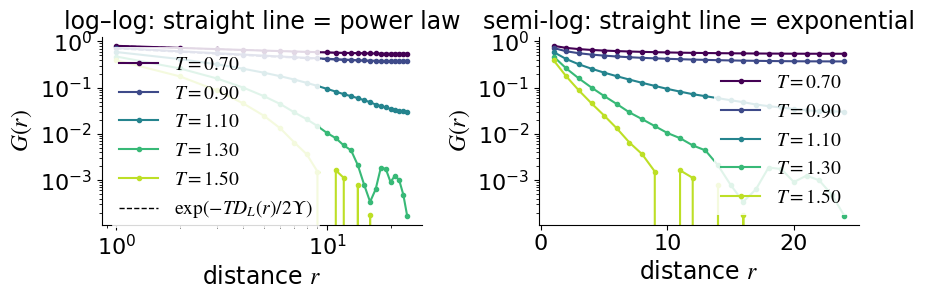

In [36]:
# figure drawn at 9.0 in and placed at 5.5 in on the slide: fonts scaled so that the text appears at about 10.5 pt
SLIDE_FONT = 17
with plt.rc_context({"font.size": SLIDE_FONT, "axes.labelsize": SLIDE_FONT, "axes.titlesize": SLIDE_FONT,
                     "xtick.labelsize": SLIDE_FONT - 1, "ytick.labelsize": SLIDE_FONT - 1, "legend.fontsize": SLIDE_FONT - 3, "mathtext.fontset": "stix", "legend.framealpha": 0.85, "legend.edgecolor": "none"}):
    fig, ax = plt.subplots(1, 2, figsize=(9.0, 3.3))
    show = [0.70, 0.90, 1.10, 1.30, 1.50]
    cols = plt.cm.viridis(np.linspace(0, 0.9, len(show)))
    for T, cl in zip(show, cols):
        i = int(np.argmin(abs(T_GRID - T)))
        ax[0].plot(r[1:], GR[48][i, 1:], "o-", ms=3, color=cl, label=f"$T={T_GRID[i]:.2f}$")
        ax[1].plot(r[1:], GR[48][i, 1:], "o-", ms=3, color=cl, label=f"$T={T_GRID[i]:.2f}$")
        if T_GRID[i] <= 0.9:                                   # renormalised spin-wave prediction (no free parameter)
            ax[0].plot(r[1:], np.exp(-T_GRID[i] / (2 * TH[48]["ups"][i, 0]) * D48[1:]), "--", color=cl, lw=1)
    ax[0].plot([], [], "k--", lw=1, label=r"$\exp(-T D_L(r)/2\Upsilon)$")
    ax[0].legend(frameon=True, fontsize=None)
    ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_title("log–log: straight line = power law")
    ax[1].set_yscale("log"); ax[1].set_title("semi-log: straight line = exponential")
    for a in ax:
        a.set_xlabel("distance $r$"); a.set_ylabel("$G(r)$")
    ax[1].legend(frameon=True, fontsize=None)
    fig.tight_layout(); savefig(fig, "xy_correlation_function.png"); plt.show()

The fits work: below $T_{\rm BKT}$ Monte Carlo and renormalised spin waves agree, and above it the correlation length falls from about 9 to 1.5 lattice spacings.
The exponent $\eta$ can also be extracted from the system-size dependence. Summing the power law over the lattice gives
$\langle\boldsymbol m^2\rangle=\frac1N\sum_{\boldsymbol r}G(\boldsymbol r)\propto L^{-\eta}$, so the effective exponent between two sizes is
$$
\eta_{\rm eff}(T)=-\frac{\ln\big(\langle\boldsymbol m^2\rangle_{L_2}/\langle\boldsymbol m^2\rangle_{L_1}\big)}{\ln(L_2/L_1)} .
$$
Below $T_{\rm BKT}$ it should follow $T/(2\pi\Upsilon)$ and reach $1/4$ at $T_{\rm BKT}$; above $T_{\rm BKT}$, $\langle\boldsymbol m^2\rangle\propto\xi^2/L^2$
once $L\gg\xi$, so $\eta_{\rm eff}$ grows towards $2$.

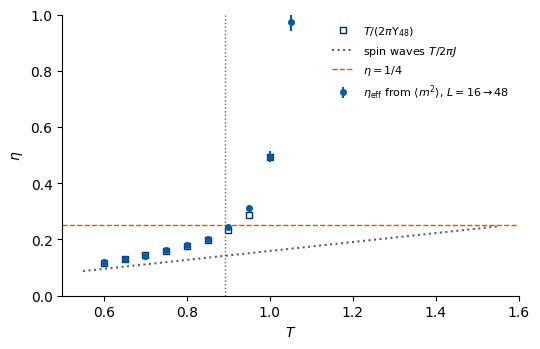

eta_eff interpolated at the literature T_BKT = 0.8929:  0.239   (theory: 0.25)
temperature where eta_eff = 1/4:  T = 0.903


In [37]:
eta_eff = -np.log(TH[48]["m2"][:, 0] / TH[16]["m2"][:, 0]) / np.log(48 / 16)
eta_eff_err = np.hypot(TH[48]["m2"][:, 1] / TH[48]["m2"][:, 0], TH[16]["m2"][:, 1] / TH[16]["m2"][:, 0]) / np.log(3)
eta_rsw = T_GRID / (2 * np.pi * TH[48]["ups"][:, 0])

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.errorbar(T_GRID, eta_eff, eta_eff_err, fmt="o", ms=4, color=UJBlue, label=r"$\eta_{\rm eff}$ from $\langle m^2\rangle$, $L=16\to48$")
ax.plot(T_GRID, eta_rsw, "s", ms=4, mfc="none", color=UJNavy, label=r"$T/(2\pi\Upsilon_{48})$")
ax.plot(Tf, Tf / (2 * np.pi), ":", color=UJGray, label=r"spin waves $T/2\pi J$")
ax.axhline(0.25, color=DSOrange, ls="--", lw=1, label=r"$\eta=1/4$")
ax.axvline(T_BKT_LIT, color=UJGray, ls=":", lw=1)
ax.set_ylim(0, 1.0); ax.set_xlabel("$T$"); ax.set_ylabel(r"$\eta$"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "xy_eta.png"); plt.show()
eta_at_Tbkt = np.interp(T_BKT_LIT, T_GRID, eta_eff)
j = np.nonzero((eta_eff[:-1] < 0.25) & (eta_eff[1:] >= 0.25))[0][0]               # first upward crossing of 1/4
T_eta_quarter = T_GRID[j] + (0.25 - eta_eff[j]) * (T_GRID[j + 1] - T_GRID[j]) / (eta_eff[j + 1] - eta_eff[j])
print(f"eta_eff interpolated at the literature T_BKT = {T_BKT_LIT:.4f}:  {eta_at_Tbkt:.3f}   (theory: 0.25)")
print(f"temperature where eta_eff = 1/4:  T = {T_eta_quarter:.3f}")
NUMBERS.update(eta_eff_at_TBKT=round(float(eta_at_Tbkt), 3), T_eta_quarter=round(float(T_eta_quarter), 3))

Below $T_{\rm BKT}$, then, the correlation function of the finite torus is described, to about 1% for $T\le0.8$ and with no free
parameter, by Gaussian spin waves with the **renormalised** stiffness $\Upsilon$; the exponent $T/(2\pi\Upsilon)$ grows with $T$, and $\eta_{\rm eff}$
from the size dependence of $\langle\boldsymbol m^2\rangle$ follows it. Above $T_{\rm BKT}$ the correlations become exponential
with a correlation length that shrinks quickly with $T$. The effective exponent passes through $\approx1/4$ close to $T_{\rm BKT}$, a second,
independent way to locate the transition (with logarithmic finite-size corrections of its own).

<hr/>
## 7. Specific heat

At an ordinary continuous transition (2D Ising) the specific heat diverges at $T_c$. At the BKT transition the free energy is
**infinitely differentiable**. The singular part of the free energy per site scales like $\xi^{-2}$ (one $k_BT$ per correlated area $\xi^2$), and with
$\xi\propto e^{b/\sqrt{t}}$, $t=T-T_{\rm BKT}$,
$$
f_{\rm sing}\propto e^{-2b/\sqrt t},
$$
a function all of whose derivatives vanish as $t\to0^+$ (an *essential singularity*). Every thermodynamic derivative, including $c=-T\,\partial^2f/\partial T^2$,
is continuous at $T_{\rm BKT}$: the transition is "of infinite order". The Monte Carlo data below show where the specific heat has its maximum.

We compute $c=\beta^2(\langle E^2\rangle-\langle E\rangle^2)/N$ from the energy fluctuations and, as a check, the numerical derivative $du/dT$ of the measured energy.
The SymPy cell verifies the essential singularity: the limit of every derivative of $e^{-2b/\sqrt t}$ at $t\to0^+$ is zero (shown for the first three).

lim t->0+ of d^0 f_sing / dt^0 = 0
lim t->0+ of d^1 f_sing / dt^1 = 0
lim t->0+ of d^2 f_sing / dt^2 = 0
lim t->0+ of d^3 f_sing / dt^3 = 0


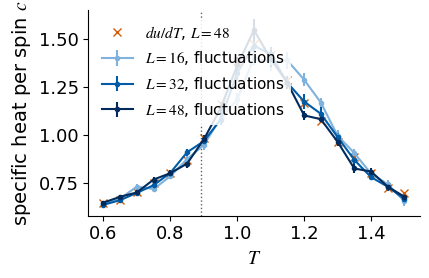

L = 16:  c_max = 1.4020 +- 0.0387 at grid T = 1.05;  parabola peak at T = 1.117
L = 32:  c_max = 1.4647 +- 0.0309 at grid T = 1.05;  parabola peak at T = 1.067
L = 48:  c_max = 1.5462 +- 0.0558 at grid T = 1.05;  parabola peak at T = 1.060
L = 16:  c at T = 0.90 (next to T_BKT) = 0.9473 +- 0.0274
L = 32:  c at T = 0.90 (next to T_BKT) = 0.9672 +- 0.0209
L = 48:  c at T = 0.90 (next to T_BKT) = 0.9763 +- 0.0214


In [38]:
# figure drawn at 4.4 in and placed at 3.3 in on the slide: fonts scaled so that the text appears at about 10.5 pt
SLIDE_FONT = 14
with plt.rc_context({"font.size": SLIDE_FONT, "axes.labelsize": SLIDE_FONT, "axes.titlesize": SLIDE_FONT,
                     "xtick.labelsize": SLIDE_FONT - 1, "ytick.labelsize": SLIDE_FONT - 1, "legend.fontsize": SLIDE_FONT - 3, "mathtext.fontset": "stix", "legend.framealpha": 0.85, "legend.edgecolor": "none"}):
    fs = sp.exp(-2 * bb / sp.sqrt(tt))
    for m_ in range(4):
        print(f"lim t->0+ of d^{m_} f_sing / dt^{m_} =", sp.limit(sp.diff(fs, tt, m_), tt, 0, "+"))

    fig, ax = plt.subplots(figsize=(4.4, 3.0))
    for L in L_LIST:
        ax.errorbar(T_GRID, TH[L]["c"][:, 0], TH[L]["c"][:, 1], fmt="o-", ms=3, color=L_COLORS[L], label=f"$L={L}$, fluctuations")
    ax.plot(T_GRID, np.gradient(TH[48]["u"][:, 0], T_GRID), "x", color=DSOrange, label=r"$du/dT$, $L=48$")
    ax.axvline(T_BKT_LIT, color=UJGray, ls=":", lw=1)
    ax.set_xlabel("$T$"); ax.set_ylabel("specific heat per spin $c$"); ax.legend(frameon=True, fontsize=None)
    fig.tight_layout(); savefig(fig, "xy_specific_heat.png"); plt.show()

    for L in L_LIST:
        c = TH[L]["c"][:, 0]; i = int(np.argmax(c))
        pk = np.polyfit(T_GRID[i - 2:i + 3], c[i - 2:i + 3], 2)                   # parabola through 5 points around the maximum
        T_pk = -pk[1] / (2 * pk[0])
        print(f"L = {L}:  c_max = {c[i]:.4f} +- {TH[L]['c'][i, 1]:.4f} at grid T = {T_GRID[i]:.2f};  parabola peak at T = {T_pk:.3f}")
        NUMBERS[f"c_peak_T_L{L}"] = round(float(T_pk), 3); NUMBERS[f"c_max_L{L}"] = round(float(c[i]), 3)
    i09 = int(np.argmin(abs(T_GRID - 0.90)))
    for L in L_LIST:
        print(f"L = {L}:  c at T = {T_GRID[i09]:.2f} (next to T_BKT) = {TH[L]['c'][i09, 0]:.4f} +- {TH[L]['c'][i09, 1]:.4f}")

The maximum of $c$ lies **above** $T_{\rm BKT}$ (at $T\approx1.06$ for $L=48$, printed above). Next to $T_{\rm BKT}$ the specific heat is the same for all three sizes within the errors, as expected for an
infinitely differentiable free energy; the height of the maximum still grows slightly between $L=16$ and $L=48$, and larger lattices would be
needed to follow it further. The two estimates of $c$ (fluctuations and $du/dT$) agree. A measurement of $c$ alone would place the
"transition" at the maximum, well above $T_{\rm BKT}$.

We can now put the two phases side by side. The schematic below shows idealised configurations on a $10\times10$ lattice, with vortices marked as in Section 4. Below $T_{\rm BKT}$, the Berezinskii–Kosterlitz–Thouless temperature, the arrows are nearly parallel and vary slowly as spin waves, and the only vortices are tightly bound vortex–antivortex pairs; the correlation function $G(r)$ decays as a power law, $G\sim r^{-\eta}$, and the helicity modulus $\Upsilon$ is positive. This phase is said to have quasi-long-range order: no magnetisation, but correlations that decay more slowly than any exponential. Above $T_{\rm BKT}$ the arrows are disordered and free vortices of both signs are scattered over the lattice; $G(r)$ decays exponentially, $G\sim e^{-r/\xi}$, and $\Upsilon=0$. Neither phase has a magnetisation in the thermodynamic limit; what distinguishes them is how the spins are correlated and whether the vortices are bound.

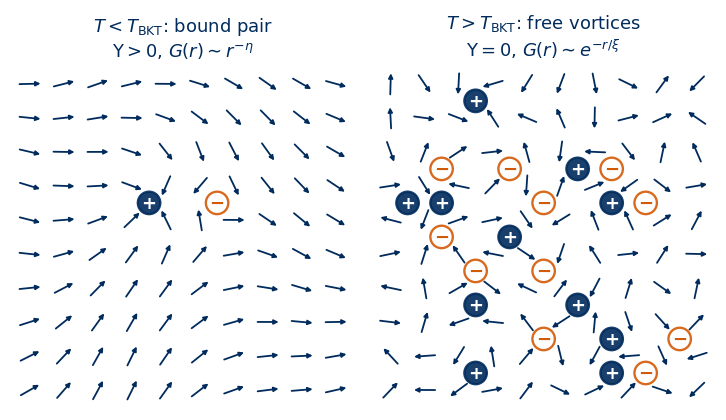

In [39]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_xy_spins(ax, theta, length=0.75, color=NAVY, lw=1.3, head=7, dot=True):
    # planar spins: an arrow of fixed length centred on every lattice site (x, y), angle theta[y, x]
    for (y, x), t in np.ndenumerate(theta):
        dx, dy = 0.5 * length * np.cos(t), 0.5 * length * np.sin(t)
        ax.annotate("", xy=(x + dx, y + dy), xytext=(x - dx, y - dy),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, mutation_scale=head, shrinkA=0, shrinkB=0))
        if dot:
            ax.plot(x, y, "o", color=GRAY, ms=1.5, zorder=1)

def plaquette_winding(theta):
    # winding number of every plaquette (lower-left corner (x, y)), corners traversed counter-clockwise
    wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi           # angle difference mapped to [-pi, pi)
    t1, t2 = theta[:-1, :-1], theta[:-1, 1:]                       # (x, y), (x+1, y)
    t3, t4 = theta[1:, 1:], theta[1:, :-1]                         # (x+1, y+1), (x, y+1)
    return np.rint((wrap(t2 - t1) + wrap(t3 - t2) + wrap(t4 - t3) + wrap(t1 - t4)) / (2 * np.pi)).astype(int)

def draw_vortex_marks(ax, w, r=0.3):
    # vortex (w = +1): navy disc with "+";  antivortex (w = -1): white disc with orange rim and "-"
    for (y, x), v in np.ndenumerate(w):
        if v != 0:
            face, edge, txt = (NAVY, NAVY, "white") if v > 0 else ("white", ORANGE, ORANGE)
            ax.add_patch(mpatches.Circle((x + 0.5, y + 0.5), r, fc=face, ec=edge, lw=1.3, zorder=6, alpha=0.9))
            ax.text(x + 0.5, y + 0.5, "+" if v > 0 else "−", color=txt, ha="center", va="center", fontsize=10,
                    fontweight="bold", zorder=7)

def sketch_xy_phases_configs():
    L = 10
    y, x = np.indices((L, L)).astype(float)
    rng = np.random.default_rng(11)                                 # fixed seed: the same schematic every time
    # low T: nearly aligned spins with a slow spin-wave twist and one tightly bound vortex-antivortex pair
    low = (0.5 * np.sin(2 * np.pi * x / L) + 0.3 * np.cos(2 * np.pi * y / L)
           + np.arctan2(y - 5.5, x - 3.5) - np.arctan2(y - 5.5, x - 5.5))
    # high T: independent random angles; the vortices are found by computing the winding of every plaquette
    high = rng.uniform(0, 2 * np.pi, (L, L))
    panels = [(low, r"$T<T_{\rm BKT}$: bound pair", r"$\Upsilon>0$, $G(r)\sim r^{-\eta}$"),
              (high, r"$T>T_{\rm BKT}$: free vortices", r"$\Upsilon=0$, $G(r)\sim e^{-r/\xi}$")]
    fig, axes = plt.subplots(1, 2, figsize=(5.5, 3.1))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.86, wspace=0.06)
    for ax, (theta, title, sub) in zip(axes, panels):
        draw_xy_spins(ax, theta, length=0.62, lw=1.0, head=5, dot=False)
        draw_vortex_marks(ax, plaquette_winding(theta), r=0.33)
        ax.set_title(f"{title}\n{sub}", fontsize=10, color=NAVY)
        ax.set_xlim(-0.5, L - 0.5); ax.set_ylim(-0.5, L - 0.5); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_xy_phases_configs()
save_sketch(fig, "sketch_xy_phase_configs.png")
plt.show()


The phase diagram of the 2D XY model has a single control parameter, the temperature, and the figure below draws it as a temperature axis together with the quantity that distinguishes the two phases, the helicity modulus. Its exact low-temperature behaviour $\Upsilon\approx J-T/4$ (Section 5.2) and its universal value $2T_{\rm BKT}/\pi$ at the transition (Section 5.3, dashed line) are drawn exactly; the curve between them is schematic. Above $T_{\rm BKT}=1/1.1199=0.8929\,J$ [Hasenbusch 2005], $\Upsilon=0$.

The BKT transition is of a kind different from the Ising transitions of Labs 010–012 and 029. At a first-order transition a first derivative of the free energy jumps; at a continuous transition the first derivatives are continuous but the correlation length diverges as a power law, $\xi\sim|T-T_c|^{-\nu}$, and the specific heat or other second derivatives diverge. At the BKT transition no symmetry is broken on either side, the correlation length diverges faster than any power, $\xi\propto\exp\big(b/\sqrt{T-T_{\rm BKT}}\big)$, and the singular part of the free energy, $f_{\rm sing}\propto e^{-2b/\sqrt t}$ (Section 7), has derivatives of all orders that vanish at $T_{\rm BKT}$: every thermodynamic derivative is continuous. Such a transition is called a transition of **infinite order**. It is visible in the jump of the helicity modulus from $2T_{\rm BKT}/\pi$ to zero and in the change from power-law to exponential decay of $G(r)$. The dashed orange marker at $T\approx1.06$ is the maximum of the specific heat for $L=48$ (Section 7): a smooth maximum above $T_{\rm BKT}$, not a transition.

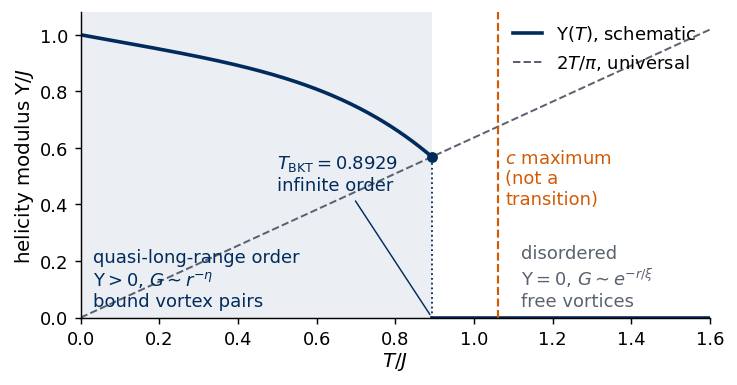

In [40]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("figures", exist_ok=True)
    for d in ("figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_xy_phase_diagram():
    T_bkt = 1.0 / 1.1199                                            # Hasenbusch (2005): beta_BKT = 1.1199
    T_cmax = 1.06                                                   # specific-heat maximum, L = 48 (Section 7)
    fig, ax = plt.subplots(figsize=(5.5, 2.9))
    fig.subplots_adjust(left=0.1, right=0.98, bottom=0.16, top=0.97)
    # helicity modulus: exact low-T slope J - T/4, universal value 2T/pi at the jump; the curve in between is schematic
    T1 = np.linspace(0, T_bkt, 200)
    ups_end = 2 * T_bkt / np.pi
    ups = (1 - T1 / 4) - (1 - T_bkt / 4 - ups_end) * (T1 / T_bkt) ** 4          # schematic interpolation
    ax.axvspan(0, T_bkt, color=NAVY, alpha=0.08, lw=0)
    ax.plot(T1, ups, color=NAVY, lw=2, label=r"$\Upsilon(T)$, schematic")
    ax.plot([T_bkt, 1.6], [0, 0], color=NAVY, lw=2)
    ax.plot([T_bkt, T_bkt], [0, ups_end], color=NAVY, lw=1, ls=":")
    TT = np.linspace(0, 1.6, 50)
    ax.plot(TT, 2 * TT / np.pi, "--", color=GRAY, lw=1.1, label=r"$2T/\pi$, universal")
    ax.plot(T_bkt, ups_end, "o", ms=5, color=NAVY)
    ax.axvline(T_cmax, color=ORANGE, lw=1.2, ls="--")
    ax.text(T_cmax + 0.02, 0.4, "$c$ maximum\n(not a\ntransition)", fontsize=10, color=ORANGE)
    ax.text(0.03, 0.04, "quasi-long-range order\n$\\Upsilon>0$, $G\\sim r^{-\\eta}$\nbound vortex pairs", fontsize=10, color=NAVY)
    ax.text(1.12, 0.04, "disordered\n$\\Upsilon=0$, $G\\sim e^{-r/\\xi}$\nfree vortices", fontsize=10, color=GRAY)
    ax.annotate(f"$T_{{\\rm BKT}}={T_bkt:.4f}$\ninfinite order", xy=(T_bkt, 0.0), xytext=(0.5, 0.45), fontsize=10, color=NAVY,
                arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
    ax.set_xlim(0, 1.6); ax.set_ylim(0, 1.08)
    ax.set_xlabel("$T/J$", labelpad=1); ax.set_ylabel(r"helicity modulus $\Upsilon/J$", labelpad=2)
    ax.legend(loc="upper left", bbox_to_anchor=(0.67, 1.0), fontsize=10, frameon=False, borderaxespad=0.2, handlelength=1.6)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_xy_phase_diagram()
save_sketch(fig, "sketch_xy_phases.png")
plt.show()


<hr/>
## 8. Consequences for machine learning

We can now collect the facts established above and ask what they imply for a learning algorithm.

| quantity | low-$T$ phase ($T<T_{\rm BKT}$) | high-$T$ phase | behaviour at $T_{\rm BKT}$ | from a single snapshot |
|---|---|---|---|---|
| $\langle|\boldsymbol m|\rangle$ | $\propto L^{-\eta(T)/2}\to0$ | $\propto\xi/L\to0$ | smooth crossover, $L$-dependent | yes |
| vortex density $n_v$ | small, activated | large | smooth, $L$-independent | yes (plaquettes) |
| $G(r)$ | power law $r^{-\eta(T)}$ | exponential $e^{-r/\xi}$ | $\eta=1/4$ | noisy, needs averaging |
| helicity modulus $\Upsilon$ | $>0$ | $0$ | universal jump $2T_{\rm BKT}/\pi$ | no (fluctuation of a global current) |
| specific heat $c$ | — | — | smooth; maximum above $T_{\rm BKT}$ | no |

The magnetisation deserves particular attention, because it is a finite-size effect. On every lattice we can simulate, $\langle|\boldsymbol m|\rangle$ is large at low $T$ and drops
around $T_{\rm BKT}$, so it *looks* like an order parameter. The figure below shows that the drop moves with $L$ and that the low-temperature value
itself decreases with $L$ as $L^{-\eta/2}$. In the thermodynamic limit both phases have $\boldsymbol m=0$.

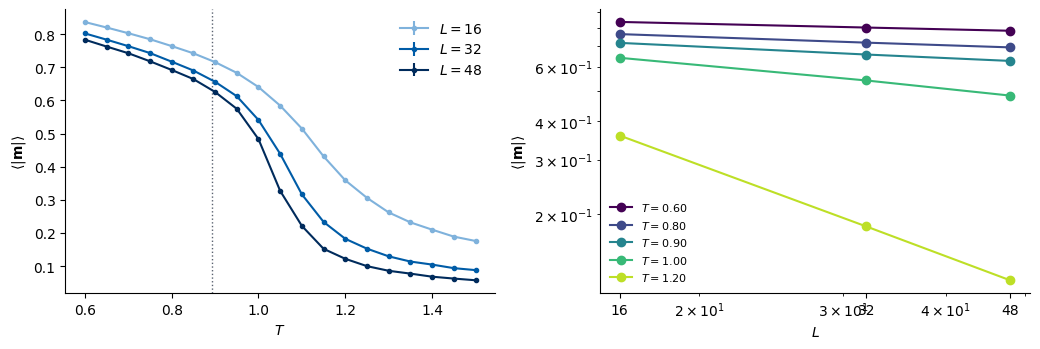

L = 16: <|m|> is closest to 0.5 at T = 1.10
L = 32: <|m|> is closest to 0.5 at T = 1.00
L = 48: <|m|> is closest to 0.5 at T = 1.00


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
for L in L_LIST:
    ax[0].errorbar(T_GRID, TH[L]["absm"][:, 0], TH[L]["absm"][:, 1], fmt="o-", ms=3, color=L_COLORS[L], label=f"$L={L}$")
ax[0].axvline(T_BKT_LIT, color=UJGray, ls=":", lw=1)
ax[0].set_xlabel("$T$"); ax[0].set_ylabel(r"$\langle|\mathbf{m}|\rangle$"); ax[0].legend(frameon=False)
for T, cl in zip([0.60, 0.80, 0.90, 1.00, 1.20], plt.cm.viridis(np.linspace(0, 0.9, 5))):
    i = int(np.argmin(abs(T_GRID - T)))
    y = [TH[L]["absm"][i, 0] for L in L_LIST]
    ax[1].plot(L_LIST, y, "o-", color=cl, label=f"$T={T_GRID[i]:.2f}$")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xticks(L_LIST); ax[1].set_xticklabels(L_LIST)
ax[1].set_xlabel("$L$"); ax[1].set_ylabel(r"$\langle|\mathbf{m}|\rangle$"); ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "xy_magnetisation_finite_size.png"); plt.show()

for L in L_LIST:
    i = int(np.argmin(abs(TH[L]["absm"][:, 0] - 0.5)))
    print(f"L = {L}: <|m|> is closest to 0.5 at T = {T_GRID[i]:.2f}")

Vortices are the relevant objects, but their density is not an order parameter either. The transition is the **unbinding** of pairs:
below $T_{\rm BKT}$ every vortex has an antivortex partner nearby; above, free vortices exist. This is a statement about the **spatial
arrangement** of defects, not about their number.

These facts have direct consequences for the anomaly-detection study later in Lecture 5. An algorithm fed with raw angles (or with $(\cos\theta_i,\sin\theta_i)$) will most easily pick up the magnetisation, the dominant variation
between low- and high-temperature snapshots of a finite lattice. Whatever "transition" it finds from that signal is a finite-size crossover
that drifts with $L$ (left panel above), not $T_{\rm BKT}$. The global rotation symmetry adds a second difficulty: two snapshots differing by $\theta_i\to\theta_i+\alpha$ are physically identical, and a representation
that is not invariant (raw angles) wastes capacity on this. A physics-informed input is the **vortex map** $w_p\in\{-1,0,1\}$ per plaquette, which is rotation invariant and consists directly of the topological objects. Even
then, a detector must be sensitive to how vortices are **arranged** (paired or free), since their density is smooth through $T_{\rm BKT}$. Finally, any temperature an algorithm singles out should be compared with the reference values of this notebook: the stiffness crossings $T^*(L)$,
the specific-heat maximum (above $T_{\rm BKT}$), and the literature value $T_{\rm BKT}=0.8929$.

<hr/>
## 9. Summary

The table collects the main statements of the notebook together with the numbers that check them.

| topic | key statement | check in this notebook (numbers from the cells above) |
|---|---|---|
| spin waves | $\langle\phi^2\rangle=\frac{T}{J}G_L$, $G_L\simeq\frac{1}{2\pi}\ln L$ | lattice sum slope $\to0.15916=1/2\pi$ |
| Mermin–Wagner | $\langle\lvert\boldsymbol m\rvert\rangle\propto L^{-T/4\pi J}\to0$ | $T=0.3$, $L=8\dots128$: exponent $0.026$ (spin waves $0.024$, with $J-T/4$: $0.026$) |
| vortex | $w=\frac1{2\pi}\oint\nabla\theta\cdot d\boldsymbol l$, $E_v=\pi J\ln(L/a)$ | SymPy contour integral; lattice slope $3.13$–$3.19$ vs $\pi$ |
| free-energy argument | $F_v=(\pi J-2T)\ln(L/a)$, $T=\pi J/2=1.571$ | overestimates $T_{\rm BKT}$ by a factor $1.76$ (screening by pairs) |
| vortex density | smooth, $L$-independent, activated at low $T$ | $n_v=0.009$ at $T=0.90$; $0.137$ at $T=1.5$; $1/3$ for random angles; $E_a\approx7.3J$ |
| helicity modulus | $\Upsilon=\frac1{2N}[J\langle C\rangle-\beta J^2\langle S^2\rangle]$, $\Upsilon\approx J-T/4$ at low $T$ | SymPy identity; finite-twist check at $T=0.7$ |
| universal jump | $\Upsilon(T_{\rm BKT}^-)=2T_{\rm BKT}/\pi$ (Nelson–Kosterlitz) | crossings $T^*(L)=0.936,\,0.921,\,0.917$ for $L=16,32,48$; extrapolated $0.897\pm0.003$ |
| literature | $T_{\rm BKT}=1/1.1199=0.8929$ (Hasenbusch 2005) | — |
| correlations | $G(r)\propto r^{-\eta}$, $\eta=T/2\pi\Upsilon$ below; $e^{-r/\xi}$ above | renormalised spin waves within $\approx1\%$ for $T\le0.8$; $\xi=5.9,\,3.3,\,2.2$ at $T=1.1,\,1.2,\,1.3$ |
| $\eta(T_{\rm BKT})=1/4$ | from the universal jump | $\eta_{\rm eff}=0.239$ at $T_{\rm BKT}$; $\eta_{\rm eff}=1/4$ at $T=0.903$ |
| specific heat | smooth at $T_{\rm BKT}$ (essential singularity) | maximum at $T\approx1.06$–$1.12$, above $T_{\rm BKT}$ |
| order parameter | none: $\langle\lvert\boldsymbol m\rvert\rangle\to0$ for all $T>0$ | $\langle\lvert\boldsymbol m\rvert\rangle$ decreases with $L$ at every $T$ |
| sampling | Metropolis $\tau_{\rm int}$ grows with $L$ | $\tau_{\rm int}(\lvert\boldsymbol m\rvert^2)$ at $T=0.9$: 38/113 (Metropolis), 3.6/6.2 (+ over-relaxation), 3.1/4.2 (+ Wolff) for $L=16/32$ |

The cell below prints the central numbers directly from the computations above.


In [42]:
print(f"T_BKT literature (Hasenbusch 2005)          : {T_BKT_LIT:.4f}")
print(f"T_BKT free-energy estimate pi J / 2          : {np.pi / 2:.4f}")
for L in L_LIST:
    print(f"crossing Upsilon_L = 2T/pi, L = {L:2d}           : {T_cross[L][0]:.4f} +- {T_cross[L][1]:.4f}")
print(f"extrapolated with b^2/(ln L)^2               : {T_BKT_fit:.3f} +- {dT_BKT_fit:.3f}")
print(f"eta_eff at T_BKT (L = 16 -> 48)              : {eta_at_Tbkt:.3f}   (theory 0.25)")
print(f"vortex density at T = 0.90, L = 48           : {TH[48]['nv'][iB, 0]:.4f}")
print(f"specific-heat maximum, L = 48                : T = {NUMBERS['c_peak_T_L48']:.3f}")
print(f"Mermin-Wagner exponent at T = {T_MW} (fit / spin waves): {-x_fit:.4f} / {T_MW / (4 * np.pi):.4f}")

T_BKT literature (Hasenbusch 2005)          : 0.8929
T_BKT free-energy estimate pi J / 2          : 1.5708
crossing Upsilon_L = 2T/pi, L = 16           : 0.9357 +- 0.0022
crossing Upsilon_L = 2T/pi, L = 32           : 0.9211 +- 0.0020
crossing Upsilon_L = 2T/pi, L = 48           : 0.9170 +- 0.0011
extrapolated with b^2/(ln L)^2               : 0.897 +- 0.003
eta_eff at T_BKT (L = 16 -> 48)              : 0.239   (theory 0.25)
vortex density at T = 0.90, L = 48           : 0.0090
specific-heat maximum, L = 48                : T = 1.060
Mermin-Wagner exponent at T = 0.3 (fit / spin waves): 0.0261 / 0.0239


<hr/>
## Exercises

### Exercise 1 — the helicity modulus from a real twist
The estimator of Section 5.1 is a second derivative. Check it with a **finite** twist: simulate $L=16$ at $T=0.7$ with every horizontal bond
twisted by $\alpha$, i.e. energy $-J\sum\cos(\Delta^x_r-\alpha)-J\sum\cos\Delta^y_r$, for $\alpha=\pm0.03$, measure the "current"
$I(\alpha)=\langle\partial H/\partial\alpha\rangle=-J\langle\sum\sin(\Delta^x_r-\alpha)\rangle$, and compare $\big(I(\alpha)-I(-\alpha)\big)/(2\alpha N)$ with $\Upsilon$ from the
estimator. (Hint: $\partial F/\partial\alpha=\langle\partial H/\partial\alpha\rangle$.)

#### Solution
A twist by $\alpha$ on every horizontal bond is the same as the substitution $\theta_{x,y}\to\theta_{x,y}-\alpha x$ inside the bulk, but it cannot
be removed on the torus because $\alpha L$ is not a multiple of $2\pi$. We write a twisted Metropolis sweep (only the horizontal neighbours carry
the extra phase: the right neighbour is seen at angle $\theta_{r+\hat x}-\alpha$, the left one at $\theta_{r-\hat x}+\alpha$) and use Metropolis only.

In [43]:
def twisted_field(theta, alpha):
    c = lambda a: jnp.cos(a); s = lambda a: jnp.sin(a)
    right, left = jnp.roll(theta, -1, -1) - alpha, jnp.roll(theta, 1, -1) + alpha
    up, down = jnp.roll(theta, -1, -2), jnp.roll(theta, 1, -2)
    return (c(right) + c(left) + c(up) + c(down), s(right) + s(left) + s(up) + s(down))

@partial(jax.jit, static_argnames=("n_equil", "n_meas"))
def twisted_run(theta0, keys, beta, alpha, n_equil, n_meas):
    colour = checkerboard(theta0.shape[-1])
    def sweep(carry, _):
        theta, key = carry
        for c in (0, 1):
            key, k1, k2 = jax.random.split(key, 3)
            new = theta + (2.0 * jax.random.uniform(k1, theta.shape) - 1.0)
            hx, hy = twisted_field(theta, alpha)
            dE = -J * (hx * (jnp.cos(new) - jnp.cos(theta)) + hy * (jnp.sin(new) - jnp.sin(theta)))
            acc = (jax.random.uniform(k2, theta.shape) < jnp.exp(-beta * dE)) & (colour == c)
            theta = jnp.where(acc, jnp.mod(new, TWO_PI), theta)
        dx = jnp.roll(theta, -1, -1) - theta - alpha
        return (theta, key), -J * jnp.sin(dx).sum()                        # dH/dalpha
    def chain(theta, key):
        carry, _ = lax.scan(sweep, (theta, key), None, length=n_equil)
        _, I = lax.scan(sweep, carry, None, length=n_meas)
        return I.mean()
    return jax.vmap(chain)(theta0, keys)

Lx, Tx, ax_ = 16, 0.7, 0.03
t0 = time.time()
keys = jax.random.split(jax.random.PRNGKey(7), 128)
I_p = np.asarray(twisted_run(jnp.zeros((128, Lx, Lx)), keys, 1 / Tx, ax_, 500, 2500))
I_m = np.asarray(twisted_run(jnp.zeros((128, Lx, Lx)), keys, 1 / Tx, -ax_, 500, 2500))
ups_twist = (I_p.mean() - I_m.mean()) / (2 * ax_ * Lx * Lx)
ups_twist_err = np.sqrt(I_p.var(ddof=1) / 128 + I_m.var(ddof=1) / 128) / (2 * ax_ * Lx * Lx)
i07 = int(np.argmin(abs(T_GRID - Tx)))
print(f"({time.time() - t0:.0f} s)")
print(f"T = {Tx}, L = {Lx}:  Upsilon from a finite twist = {ups_twist:.3f} +- {ups_twist_err:.3f}   "
      f"estimator (data set) = {TH[16]['ups'][i07, 0]:.3f} +- {TH[16]['ups'][i07, 1]:.3f}")

(20 s)
T = 0.7, L = 16:  Upsilon from a finite twist = 0.777 +- 0.001   estimator (data set) = 0.778 +- 0.001


The two numbers agree within the statistical error: the fluctuation formula is the curvature of the free energy with respect to a twist.
(Mixed into the error is a small $O(\alpha^2)$ systematic of the finite difference.)

### Exercise 2 — spin waves in three dimensions
Compute the lattice sum $G_L=\frac1N\sum_{\boldsymbol k\ne0}1/\lambda_{\boldsymbol k}$ in $d=3$ for $L=4,\dots,64$ and compare with $d=2$.
What does the result imply for the magnetisation of the 3D XY model at low $T$ in the Gaussian approximation?

#### Solution

In [44]:
print("   L     G_L (d = 2)   G_L (d = 3)")
for L in [4, 8, 16, 32, 64]:
    print(f"{L:4d}    {lattice_G(L, 2):.5f}       {lattice_G(L, 3):.5f}")

   L     G_L (d = 2)   G_L (d = 3)
   4    0.26823       0.19753
   8    0.37929       0.22461
  16    0.48992       0.23863
  32    0.60033       0.24568
  64    0.71067       0.24920


In $d=2$ the sum keeps growing by $\frac{\ln2}{2\pi}\approx0.110$ per doubling of $L$; in $d=3$ the increments shrink like $1/L$ and $G_L$
converges, because $\int d^3k/k^2=4\pi\int dk$ is finite at small $k$. The angle fluctuations stay bounded, so
$\langle|\boldsymbol m|\rangle\to e^{-TG_\infty/2J}>0$: in three dimensions spin waves do **not** destroy long-range order, and the 3D XY model has a
conventional ordered phase with $\boldsymbol m\ne0$.

### Exercise 3 — renormalised spin waves at $T=0.6$
At $T=0.6$, fit $\langle|\boldsymbol m|\rangle\propto L^{-x}$ to the data set ($L=16,32,48$) and compare $x$ with the bare spin-wave value $T/(4\pi J)$ and
with the renormalised value $T/(4\pi\Upsilon)$, with $\Upsilon$ measured at $L=48$.

#### Solution

In [45]:
i = 0
Tq0 = T_GRID[i]
x06 = -np.polyfit(np.log(L_LIST), np.log([TH[L]["absm"][i, 0] for L in L_LIST]), 1)[0]
print(f"T = {Tq0:.2f}: fitted x = {x06:.4f};  T/(4 pi J) = {Tq0 / (4 * np.pi):.4f};  T/(4 pi Upsilon_48) = {Tq0 / (4 * np.pi * TH[48]['ups'][i, 0]):.4f}")
print(f"stiffness reduction 1 - Upsilon_48 / J at T = {Tq0:.2f}: {100 * (1 - TH[48]['ups'][i, 0] / J):.1f} %")

T = 0.60: fitted x = 0.0600;  T/(4 pi J) = 0.0477;  T/(4 pi Upsilon_48) = 0.0582
stiffness reduction 1 - Upsilon_48 / J at T = 0.60: 18.0 %


The measured exponent is larger than the bare spin-wave value and close to the renormalised one: at $T=0.6$ bound vortex pairs and anharmonic
terms already soften the stiffness by the percentage printed above, and the long-distance physics is that of spin waves with stiffness $\Upsilon$, not $J$.

<hr/>
## References

**Original papers**
* V. L. Berezinskii, *Destruction of long-range order in one-dimensional and two-dimensional systems having a continuous symmetry group. I. Classical systems*,
  Sov. Phys. JETP **32**, 493 (1971), [JETP archive](http://www.jetp.ras.ru/cgi-bin/e/index/e/32/3/p493?a=list)
* V. L. Berezinskii, *Destruction of long-range order in one-dimensional and two-dimensional systems possessing a continuous symmetry group. II. Quantum systems*,
  Sov. Phys. JETP **34**, 610 (1972), [JETP archive](http://www.jetp.ras.ru/cgi-bin/e/index/e/34/3/p610?a=list)
* J. M. Kosterlitz, D. J. Thouless, *Ordering, metastability and phase transitions in two-dimensional systems*, J. Phys. C **6**, 1181 (1973),
  [doi:10.1088/0022-3719/6/7/010](https://doi.org/10.1088/0022-3719/6/7/010)
* J. M. Kosterlitz, *The critical properties of the two-dimensional xy model*, J. Phys. C **7**, 1046 (1974),
  [doi:10.1088/0022-3719/7/6/005](https://doi.org/10.1088/0022-3719/7/6/005)
* D. R. Nelson, J. M. Kosterlitz, *Universal jump in the superfluid density of two-dimensional superfluids*, Phys. Rev. Lett. **39**, 1201 (1977),
  [doi:10.1103/PhysRevLett.39.1201](https://doi.org/10.1103/PhysRevLett.39.1201)
* N. D. Mermin, H. Wagner, *Absence of ferromagnetism or antiferromagnetism in one- or two-dimensional isotropic Heisenberg models*,
  Phys. Rev. Lett. **17**, 1133 (1966), [doi:10.1103/PhysRevLett.17.1133](https://doi.org/10.1103/PhysRevLett.17.1133)
* D. J. Bishop, J. D. Reppy, *Study of the superfluid transition in two-dimensional $^4$He films*, Phys. Rev. Lett. **40**, 1727 (1978),
  [doi:10.1103/PhysRevLett.40.1727](https://doi.org/10.1103/PhysRevLett.40.1727)
* M. Hasenbusch, *The two-dimensional XY model at the transition temperature: a high-precision Monte Carlo study*, J. Phys. A **38**, 5869 (2005),
  [doi:10.1088/0305-4470/38/26/003](https://doi.org/10.1088/0305-4470/38/26/003) — source of $\beta_{\rm BKT}=1.1199$.
* U. Wolff, *Collective Monte Carlo updating for spin systems*, Phys. Rev. Lett. **62**, 361 (1989),
  [doi:10.1103/PhysRevLett.62.361](https://doi.org/10.1103/PhysRevLett.62.361)
* M. Creutz, *Overrelaxation and Monte Carlo simulation*, Phys. Rev. D **36**, 515 (1987),
  [doi:10.1103/PhysRevD.36.515](https://doi.org/10.1103/PhysRevD.36.515)
* F. R. Brown, T. J. Woch, *Overrelaxed heat-bath and Metropolis algorithms for accelerating pure gauge Monte Carlo calculations*,
  Phys. Rev. Lett. **58**, 2394 (1987), [doi:10.1103/PhysRevLett.58.2394](https://doi.org/10.1103/PhysRevLett.58.2394)
* The Nobel Prize in Physics 2016, [nobelprize.org/prizes/physics/2016/summary](https://www.nobelprize.org/prizes/physics/2016/summary/)

**Textbooks**
* P. M. Chaikin, T. C. Lubensky, *Principles of Condensed Matter Physics*, Cambridge University Press (1995),
  [doi:10.1017/CBO9780511813467](https://doi.org/10.1017/CBO9780511813467)
* M. Kardar, *Statistical Physics of Fields*, Cambridge University Press (2007),
  [doi:10.1017/CBO9780511815881](https://doi.org/10.1017/CBO9780511815881)
* M. E. J. Newman, G. T. Barkema, *Monte Carlo Methods in Statistical Physics*, Oxford University Press (1999),
  [doi:10.1093/oso/9780198517962.001.0001](https://doi.org/10.1093/oso/9780198517962.001.0001)

The final cell collects the numbers quoted in this notebook, together with its running time, and prints them.